<a href="https://colab.research.google.com/github/naman39910/DeepCSAT-Customer-Satisfaction-Prediction/blob/main/DeepCSAT_E_Commerce_Customer_Satisfaction_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Name - DeepCSAT: E-Commerce Customer Satisfaction Score Prediction


##### **Project Type**    - EDA/Regression/Classification/Unsupervised / Deep Learning (ANN)
##### **Contribution**    - Individual


# **Project Summary -**

DeepCSAT: E-Commerce Customer Satisfaction Score Prediction is an end-to-end deep learning and customer-experience analytics project designed to predict customer satisfaction (CSAT Score) from e-commerce support interaction logs, timestamps, order and product attributes, agent metadata, and customer feedback remarks. In high-volume e-commerce operations, monitoring satisfaction accurately and proactively is vital to sustaining customer retention, brand trust, and repeat purchase value. Traditional post-interaction surveys are inherently reactive—they capture feedback only after an issue has already occurred and often suffer from low response rates or reporting bias. By developing a deep learning model that estimates satisfaction from interaction context and customer feedback, support teams can identify dissatisfaction risks earlier, prioritize high-impact service bottlenecks, and strengthen customer loyalty.

The project follows a structured data science workflow across data integrity and wrangling, exploratory data analysis (EDA) and statistical hypothesis testing, feature engineering and preprocessing, neural network modeling and optimization, evaluation, insight generation, and local deployment. During initial data inspection and cleaning on the customer support dataset (85,907 interaction records across channels, issue categories, sub-categories, shifts, and product lines), we examine dataset dimensions, duplicates, missing values, column types, and target distribution. Missing values across numerical, categorical, and text fields are handled systematically using median imputation for skewed numerical attributes, mode or explicit "Unknown" / "MISSING" labels and missingness indicators for categorical fields, and empty strings or indicators for Customer Remarks, preserving analytical completeness while avoiding unintended leakage.

In the exploratory data analysis and hypothesis testing stages, we analyze how CSAT Score varies across operational dimensions including channel_name, category, Sub-category, Agent Shift, Tenure Bucket, Item_price, connected_handling_time, and interaction timing. Statistical tests—such as One-Way ANOVA across agent shifts and correlation analysis across continuous service and pricing variables—help verify whether observed differences represent statistically meaningful relationships rather than random noise. These findings guide feature engineering and preprocessing, where raw attributes, timestamps, categorical variables, and customer remarks are prepared cleanly through encoding, scaling, and train/test separation.

For modeling, we build a deep learning Artificial Neural Network (ANN) in Python using TensorFlow/Keras alongside scikit-learn preprocessing and evaluation tools. The network uses dense layers, non-linear activations, normalization, and regularization techniques such as dropout—supported by training optimizations including batch processing, learning rate scheduling, and early stopping—to capture non-linear patterns across engineered inputs. Model performance is evaluated across held-out data using metrics aligned with the CSAT task (such as MAE, RMSE, and R² for continuous score prediction, or accuracy, precision, recall, F1-score, and confusion matrices for satisfaction classification), checking for overfitting and generalization.

Beyond quantitative metrics, the project translates analytical findings and model predictions into actionable business recommendations, highlighting how handling durations, response delays, issue categories, agent shifts, and order values relate to customer dissatisfaction and where service workflows can be improved. Finally, we save the trained pipeline and deploy it locally so predictions can be demonstrated interactively during the walkthrough. Overall, DeepCSAT shows how deep learning and structured analytics can turn raw support records into proactive customer-experience decisions.

# **GitHub Link -**

https://github.com/naman39910/DeepCSAT-Customer-Satisfaction-Prediction

# **Problem Statement**


In high-volume e-commerce operations, measuring and maintaining Customer Satisfaction (CSAT Score) accurately and proactively is critical to customer retention, brand trust, and repeat revenue. Traditional post-interaction surveys are inherently reactive—they collect feedback only after an issue has already occurred, suffer from low or biased response rates, and leave support teams without early warning signals when an interaction is heading toward dissatisfaction.

Using the e-commerce customer support dataset (85,907 interaction records spanning support channels, issue categories and sub-categories, product categories, item prices, handling and response timestamps, agent shift and tenure attributes, and customer feedback remarks), the objective of this project is to build an end-to-end Artificial Neural Network (ANN) solution that:


**1**.**Predicts Customer Satisfaction** (CSAT Score) from interaction, operational, and customer feedback signals so support teams can anticipate satisfaction outcomes earlier rather than waiting solely for manual survey responses.

**2**.**Identifies Key Drivers of Dissatisfaction** across support channels, issue categories, agent shifts/tenure, item price tiers, handling durations, and response/resolution delays, supported by exploratory analysis, statistical hypothesis testing, and engineered features.

**3**.**Delivers Actionable Operational Insights & Local Deployment** that help customer support leaders prioritize service bottlenecks, improve response and resolution workflows, and demonstrate real-time or batch CSAT predictions locally.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [63]:
# Import Libraries
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder, OneHotEncoder

### Dataset Loading

In [64]:
# Load Dataset
file_path ="/content/eCommerce_Customer_support_data.csv"

df = pd.read_csv(file_path)


print("Dataset loaded successfully.")

Dataset loaded successfully.


### Dataset First View

In [65]:
# Dataset First Look
date_cols = ["order_date_time", "Issue_reported at", "issue_responded", "Survey_response_Date"]
for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], dayfirst=True, errors="coerce")

display(df.head(5))

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaT,2023-08-01 11:13:00,2023-08-01 11:47:00,2023-08-01,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaT,2023-08-01 12:52:00,2023-08-01 12:54:00,2023-08-01,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaT,2023-08-01 20:16:00,2023-08-01 20:38:00,2023-08-01,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaT,2023-08-01 20:56:00,2023-08-01 21:16:00,2023-08-01,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaT,2023-08-01 10:30:00,2023-08-01 10:32:00,2023-08-01,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [66]:
# Dataset Rows & Columns count
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("Column Names:", df.columns.tolist())

Total Rows: 85907
Total Columns: 20
Column Names: ['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'connected_handling_time', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']


### Dataset Information

In [67]:
# Dataset Info
# Inspect schema, non-null counts, data types, and memory footprint
print("DataFrame Shape:", df.shape)
print("\nDataFrame Info:")
df.info()

# Summary table of column types and non-null counts
schema_df = pd.DataFrame({
    "Column": df.columns,
    "Dtype": df.dtypes.astype(str).values,
    "Non_Null_Count": df.notnull().sum().values,
    "Null_Count": df.isnull().sum().values,
    "Null_Pct": (df.isnull().mean().values * 100).round(2),
})
display(schema_df)

DataFrame Shape: (85907, 20)

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Unique id                85907 non-null  object        
 1   channel_name             85907 non-null  object        
 2   category                 85907 non-null  object        
 3   Sub-category             85907 non-null  object        
 4   Customer Remarks         28742 non-null  object        
 5   Order_id                 67675 non-null  object        
 6   order_date_time          17214 non-null  datetime64[ns]
 7   Issue_reported at        85907 non-null  datetime64[ns]
 8   issue_responded          85907 non-null  datetime64[ns]
 9   Survey_response_Date     85907 non-null  datetime64[ns]
 10  Customer_City            17079 non-null  object        
 11  Product_category         17196 non-null  object

,Column,Dtype,Non_Null_Count,Null_Count,Null_Pct
0,Unique id,object,85907,0,0.00
1,channel_name,object,85907,0,0.00
2,category,object,85907,0,0.00
3,Sub-category,object,85907,0,0.00
4,Customer Remarks,object,28742,57165,66.54
5,Order_id,object,67675,18232,21.22
6,order_date_time,datetime64[ns],17214,68693,79.96
7,Issue_reported at,datetime64[ns],85907,0,0.00
8,issue_responded,datetime64[ns],85907,0,0.00
9,Survey_response_Date,datetime64[ns],85907,0,0.00


#### Duplicate Values

In [68]:
# Dataset Duplicate Value Count
exact_dupes = df.duplicated().sum()
unique_id_dupes = df["Unique id"].duplicated().sum() if "Unique id" in df.columns else 0

print(f"Exact duplicate rows: {exact_dupes}")
print(f"Duplicate 'Unique id' entries: {unique_id_dupes}")

Exact duplicate rows: 0
Duplicate 'Unique id' entries: 0


#### Missing Values/Null Values

In [69]:
# Missing Values/Null Values Count
missing_df = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Pct (%)": (df.isnull().mean() * 100).round(2),
}).sort_values(by="Missing_Count", ascending=False)

print("Columns with Missing Values:")
display(missing_df[missing_df["Missing_Count"] > 0])

print("\nTotal missing cells across dataset:", int(df.isnull().sum().sum()))

Columns with Missing Values:


,Missing_Count,Missing_Pct (%)
connected_handling_time,85665,99.72
Customer_City,68828,80.12
Product_category,68711,79.98
Item_price,68701,79.97
order_date_time,68693,79.96
Customer Remarks,57165,66.54
Order_id,18232,21.22



Total missing cells across dataset: 435995


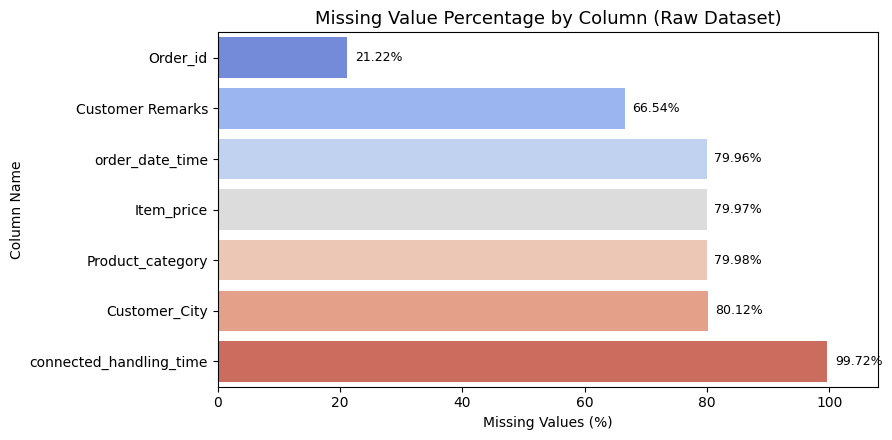

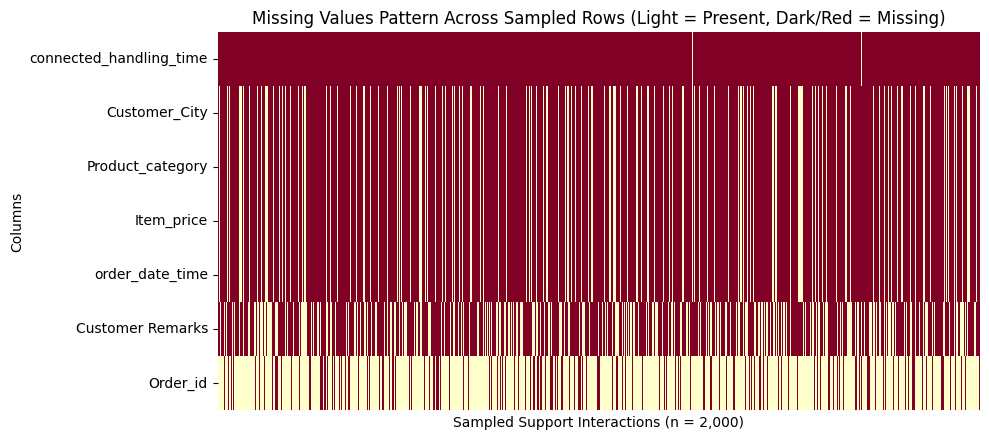

In [70]:
# Visualizing the missing values
# 1. Compute missing percentages for columns that have missing values
missing_pct = (df.isnull().mean() * 100).round(2)
missing_cols = missing_pct[missing_pct > 0].sort_values(ascending=True)

# 2. Horizontal bar chart of missing values (%)
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(
    x=missing_cols.values,
    y=missing_cols.index,
    palette="coolwarm"
)
plt.title("Missing Value Percentage by Column (Raw Dataset)", fontsize=13)
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Name")
plt.xlim(0, 108)

for i, val in enumerate(missing_cols.values):
    ax.text(val + 1.2, i, f"{val:.2f}%", va="center", fontsize=9)

plt.tight_layout()
plt.show()

# 3. Missingness pattern heatmap (sampled for fast rendering on 85,907 rows)
sample_df = df[missing_cols.index[::-1]].sample(n=min(2000, len(df)), random_state=42)
plt.figure(figsize=(10, 4.5))
sns.heatmap(
    sample_df.isnull().T,
    cbar=False,
    cmap="YlOrRd",
    yticklabels=True,
    xticklabels=False
)
plt.title("Missing Values Pattern Across Sampled Rows (Light = Present, Dark/Red = Missing)", fontsize=12)
plt.xlabel("Sampled Support Interactions (n = 2,000)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

#### Handled Missing Values/Null Values

In [71]:
# Handled Missing Value
# Work on a clean copy so raw `df` remains intact for inspection
df_clean = df.copy()

# 1. Create explicit missingness indicator flags BEFORE imputing
flag_cols = [
    "order_date_time",
    "Customer_City",
    "Product_category",
    "Item_price",
    "connected_handling_time",
    "Customer Remarks",
    "Order_id",
]
for col in flag_cols:
    if col in df_clean.columns:
        df_clean[f"{col}_was_missing"] = df_clean[col].isnull().astype(int)

# 2. Handle Order_id (identifier): fill missing with 'No_Order_ID' so counts/checks are explicit
if "Order_id" in df_clean.columns:
    df_clean["Order_id"] = df_clean["Order_id"].fillna("No_Order_ID")

# 3. Handle Customer Remarks (text): fill missing with empty string ''
if "Customer Remarks" in df_clean.columns:
    df_clean["Customer Remarks"] = df_clean["Customer Remarks"].fillna("").astype(str).str.strip()

# 4. Handle high-missing categorical columns with 'Unknown'
for col in ["Customer_City", "Product_category"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("Unknown").astype(str)

# 5. Handle numeric columns (Item_price, connected_handling_time) with median
# (Keep raw CSAT Score untouched here; never impute or scale target in cleaning)
for col in ["Item_price", "connected_handling_time"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)

# 6. Keep order_date_time as parsed datetime (NaT preserved where missing so time-delta logic stays safe)
if "order_date_time" in df_clean.columns:
    df_clean["order_date_time"] = pd.to_datetime(
        df_clean["order_date_time"], dayfirst=True, errors="coerce"
    )

# Verify remaining nulls (only order_date_time should still have NaT if kept as datetime)
remaining_nulls = df_clean.isnull().sum()
print("Remaining null counts after handling:")
print(remaining_nulls[remaining_nulls > 0])
print("\nTotal non-datetime nulls remaining:", int(df_clean.drop(columns=["order_date_time"], errors="ignore").isnull().sum().sum()))
print("Shape after missing-value handling:", df_clean.shape)

Remaining null counts after handling:
order_date_time    68693
dtype: int64

Total non-datetime nulls remaining: 0
Shape after missing-value handling: (85907, 27)


### What did you know about your dataset?

**here are the key findings:**

*  **Dataset Scale & Integrity:** The dataset contains 85,907 customer support
interaction records and 20 initial columns, with 0 exact duplicate rows and 0 duplicate Unique id entries (85,907 unique IDs).

* **Target Variable (CSAT Score):** All 85,907 rows have a non-null CSAT Score (int64, values 1 to 5, mean ~4.24, median 5.0), showing a strong skew toward higher satisfaction ratings (4 and 5) alongside lower-score cases (1–3) that represent service friction.

* **Feature Types & Coverage:** The raw schema combines numerical fields (Item_price, connected_handling_time, and CSAT Score), timestamp/date fields (order_date_time, Issue_reported at, issue_responded, Survey_response_Date), categorical hierarchies (channel_name, category, Sub-category, Customer_City, Product_category, Agent_name, Supervisor, Manager, Tenure Bucket, Agent Shift), and identifiers/text (Unique id, Order_id, Customer Remarks).

* **Missing Data Patterns:** There are 435,995 total missing cells across 7 columns—most notably connected_handling_time (99.72% missing, only 242 non-null rows), Customer_City (80.12% missing), Product_category (79.98% missing), Item_price (79.97% missing), order_date_time (79.96% missing), Customer Remarks (66.54% missing, 28,742 non-null rows), and Order_id (21.22% missing).

* **Modeling Readiness & Caveats:** Because key context fields (order_date_time, Item_price, Customer_City, Product_category, Customer Remarks, and connected_handling_time) have high missingness rather than uniform completeness, rows should not simply be dropped blindly; instead, deliberate missingness handling, feature engineering (such as response/resolution timing and text signals), and leak-free preprocessing are essential before training the Artificial Neural Network (ANN).

## ***2. Understanding Your Variables***

In [72]:
# Dataset Columns
# Inspect all columns and their current data types
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col:<26} -> {df[col].dtype}")

 1. Unique id                  -> object
 2. channel_name               -> object
 3. category                   -> object
 4. Sub-category               -> object
 5. Customer Remarks           -> object
 6. Order_id                   -> object
 7. order_date_time            -> datetime64[ns]
 8. Issue_reported at          -> datetime64[ns]
 9. issue_responded            -> datetime64[ns]
10. Survey_response_Date       -> datetime64[ns]
11. Customer_City              -> object
12. Product_category           -> object
13. Item_price                 -> float64
14. connected_handling_time    -> float64
15. Agent_name                 -> object
16. Supervisor                 -> object
17. Manager                    -> object
18. Tenure Bucket              -> object
19. Agent Shift                -> object
20. CSAT Score                 -> int64


In [73]:
# Dataset Describe
# Numerical summary (including target CSAT Score)
print("=== Numerical Summary ===")
display(df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])

# Non-numeric summary (categorical, text, and datetime columns)
print("\n=== Non-Numeric Summary ===")
display(df.describe(exclude=[np.number]).T[["count", "unique", "top", "freq"]])

=== Numerical Summary ===


,count,mean,std,min,25%,50%,75%,max
order_date_time,17214,2023-07-28 15:49:45.820843520,NaN,2022-01-16 13:15:00,2023-07-27 22:49:15,2023-08-04 22:16:30,2023-08-10 07:30:15,2023-12-08 23:36:00
Issue_reported at,85907,2023-08-16 22:29:05.784394752,NaN,2023-07-28 20:42:00,2023-08-09 12:48:00,2023-08-16 18:22:00,2023-08-24 17:33:30,2023-08-31 23:58:00
issue_responded,85907,2023-08-17 00:45:58.980990976,NaN,2023-08-01 00:00:00,2023-08-09 15:02:30,2023-08-16 20:57:00,2023-08-24 19:27:00,2023-08-31 23:59:00
Survey_response_Date,85907,2023-08-16 10:18:31.760392192,NaN,2023-08-01 00:00:00,2023-08-09 00:00:00,2023-08-16 00:00:00,2023-08-24 00:00:00,2023-08-31 00:00:00
Item_price,17206.0,5660.774846,12825.728411,0.0,392.0,979.0,2699.75,164999.0
connected_handling_time,242.0,462.400826,246.295037,0.0,293.0,427.0,592.25,1986.0
CSAT Score,85907.0,4.242157,1.378903,1.0,4.0,5.0,5.0,5.0



=== Non-Numeric Summary ===


,count,unique,top,freq
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1
channel_name,85907,3,Inbound,68142
category,85907,12,Returns,44097
Sub-category,85907,57,Reverse Pickup Enquiry,22389
Customer Remarks,28742,18231,Good,1390
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1
order_date_time,17214,NaN,NaN,NaN
Issue_reported at,85907,NaN,NaN,NaN
issue_responded,85907,NaN,NaN,NaN
Survey_response_Date,85907,NaN,NaN,NaN


### Variables Description

**Identifiers:**

Unique id: Unique identifier for each customer support interaction (85,907 unique records).

Order_id: Identifier linking the interaction to a customer order (67,675 non-null; 21.22% missing).

**Interaction & Issue Details:**

channel_name: Support channel (3 unique values, e.g., Inbound, Outcall; Inbound is most frequent with 68,142 rows).

category: Broad issue type (12 unique values, e.g., Returns, Order Related, Product Queries, Cancellation).

Sub-category: Detailed issue classification (57 unique values, e.g., Reverse Pickup Enquiry, Installation/demo).

**Customer Feedback & Location:**

Customer Remarks: Free-text customer feedback (28,742 non-null; 66.54% missing; 18,231 unique non-null remarks).

Customer_City: City of the customer (17,079 non-null; 80.12% missing).

**Order & Product Context:**

Product_category: Category of the purchased item (17,196 non-null; 79.98% missing).

Item_price: Price of the item (17,206 non-null; 79.97% missing).

**Timestamps & Handling Time:**

order_date_time: Timestamp when the order was placed (17,214 non-null; 79.96% missing).

Issue_reported at: Timestamp when the support issue was reported (85,907 non-null).

issue_responded: Timestamp when support responded to the issue (85,907 non-null).

Survey_response_Date: Date when the CSAT survey response was submitted (85,907 non-null).

connected_handling_time: Duration of connected agent handling (242 non-null; 99.72% missing).

**Agent & Team Hierarchy:**

Agent_name (1,371 unique), Supervisor (40 unique), Manager (6 unique), Tenure Bucket (5 unique), and Agent Shift (5 unique, e.g., Morning, Evening).

**Target Variable:**

CSAT Score: Customer satisfaction rating on a 1 to 5 integer scale (85,907 non-null; mean 4.24, median 5.0, std 1.38).

### Check Unique Values for each variable.

In [74]:
# Check Unique Values for each variable.
unique_table = pd.DataFrame({
    "Column": df.columns,
    "Dtype": df.dtypes.astype(str).values,
    "Unique_Count": [df[c].nunique(dropna=True) for c in df.columns],
    "Sample_Values": [
        list(df[c].dropna().unique()[:5]) if df[c].nunique(dropna=True) <= 12
        else list(df[c].dropna().unique()[:3]) + ["..."]
        for c in df.columns
    ]
})
display(unique_table)

,Column,Dtype,Unique_Count,Sample_Values
0,Unique id,object,85907,"[7e9ae164-6a8b-4521-a2d4-58f7c9fff13f, b07ec1b..."
1,channel_name,object,3,"[Outcall, Inbound, Email]"
2,category,object,12,"[Product Queries, Order Related, Returns, Canc..."
3,Sub-category,object,57,"[Life Insurance, Product Specific Information,..."
4,Customer Remarks,object,18231,"[Very good, Shopzilla app and it's all coustom..."
5,Order_id,object,67675,"[c27c9bb4-fa36-4140-9f1f-21009254ffdb, d406b0c..."
6,order_date_time,datetime64[ns],13766,"[2023-07-19 23:50:00, 2023-05-06 21:41:00, 202..."
7,Issue_reported at,datetime64[ns],30923,"[2023-08-01 11:13:00, 2023-08-01 12:52:00, 202..."
8,issue_responded,datetime64[ns],30262,"[2023-08-01 11:47:00, 2023-08-01 12:54:00, 202..."
9,Survey_response_Date,datetime64[ns],31,"[2023-08-01 00:00:00, 2023-08-02 00:00:00, 202..."


## 3. ***Data Wrangling***

### Data Wrangling Code

In [75]:
# Write your code to make your dataset analysis ready.
# ============================================================
# 3. Data Wrangling — Clean, Standardize & Prepare for EDA/ML
# ============================================================

# Start from raw dataset or clean copy so execution is repeatable
if 'df_raw' in globals():
    df_wrangled = df_raw.copy()
else:
    df_wrangled = pd.read_csv("/content/eCommerce_Customer_support_data.csv")

# 1. Remove exact duplicate rows (if any)
before_dupes = len(df_wrangled)
df_wrangled = df_wrangled.drop_duplicates().copy()
print(f"Duplicates removed: {before_dupes - len(df_wrangled)}")

# 2. Parse timestamp columns safely (coerce invalid/missing values to NaT)
dt_cols = ["order_date_time", "Issue_reported at", "issue_responded", "Survey_response_Date"]
for col in dt_cols:
    if col in df_wrangled.columns:
        df_wrangled[col] = pd.to_datetime(df_wrangled[col], dayfirst=True, errors="coerce")

# 3. Capture missingness flags BEFORE imputing high-missing fields
missing_flag_cols = [
    "order_date_time",
    "Customer_City",
    "Product_category",
    "Item_price",
    "connected_handling_time",
    "Customer Remarks",
    "Order_id",
]
for col in missing_flag_cols:
    if col in df_wrangled.columns:
        df_wrangled[f"{col}_was_missing"] = df_wrangled[col].isnull().astype(int)

# 4. Handle missing values by column type
if "Order_id" in df_wrangled.columns:
    df_wrangled["Order_id"] = df_wrangled["Order_id"].fillna("No_Order_ID").astype(str)

if "Customer Remarks" in df_wrangled.columns:
    df_wrangled["Customer Remarks"] = df_wrangled["Customer Remarks"].fillna("").astype(str).str.strip()

for cat_col in ["Customer_City", "Product_category"]:
    if cat_col in df_wrangled.columns:
        df_wrangled[cat_col] = df_wrangled[cat_col].fillna("Unknown").astype(str).str.strip()

for num_col in ["Item_price", "connected_handling_time"]:
    if num_col in df_wrangled.columns:
        df_wrangled[num_col] = pd.to_numeric(df_wrangled[num_col], errors="coerce")
        df_wrangled[num_col] = df_wrangled[num_col].fillna(df_wrangled[num_col].median())

# Ensure target CSAT Score is clean integer (1 to 5)
if "CSAT Score" in df_wrangled.columns:
    df_wrangled["CSAT Score"] = pd.to_numeric(df_wrangled["CSAT Score"], errors="coerce").astype(int)

# 5. Create core operational time-delta & text-length features for EDA & modeling
if {"issue_responded", "Issue_reported at"}.issubset(df_wrangled.columns):
    df_wrangled["response_time_min"] = (
        (df_wrangled["issue_responded"] - df_wrangled["Issue_reported at"]).dt.total_seconds() / 60.0
    ).clip(lower=0)

if {"Issue_reported at", "order_date_time"}.issubset(df_wrangled.columns):
    df_wrangled["order_to_issue_hrs"] = (
        (df_wrangled["Issue_reported at"] - df_wrangled["order_date_time"]).dt.total_seconds() / 3600.0
    ).clip(lower=0)

if "Customer Remarks" in df_wrangled.columns:
    df_wrangled["remark_char_len"] = df_wrangled["Customer Remarks"].str.len()
    df_wrangled["remark_word_count"] = df_wrangled["Customer Remarks"].str.split().str.len()

# Sync df_clean so downstream cells have a consistent wrangled dataset
df_clean = df_wrangled.copy()

# 6. Verification checks
non_dt_nulls = int(df_clean.drop(columns=["order_date_time"], errors="ignore").isnull().sum().sum())
print(f"Wrangled shape: {df_clean.shape}")
print(f"Non-datetime missing values remaining: {non_dt_nulls}")
print(f"order_date_time missing (NaT preserved): {df_clean['order_date_time'].isna().sum() if 'order_date_time' in df_clean.columns else 0}")
display(df_clean.head(3))

Duplicates removed: 0
Wrangled shape: (85907, 31)
Non-datetime missing values remaining: 68693
order_date_time missing (NaT preserved): 68693


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,...,Customer_City_was_missing,Product_category_was_missing,Item_price_was_missing,connected_handling_time_was_missing,Customer Remarks_was_missing,Order_id_was_missing,response_time_min,order_to_issue_hrs,remark_char_len,remark_word_count
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaT,2023-08-01 11:13:00,2023-08-01 11:47:00,2023-08-01,...,1,1,1,1,1,0,34.0,NaN,0,0
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,,d406b0c7-ce17-4654-b9de-f08d421254bd,NaT,2023-08-01 12:52:00,2023-08-01 12:54:00,2023-08-01,...,1,1,1,1,1,0,2.0,NaN,0,0
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaT,2023-08-01 20:16:00,2023-08-01 20:38:00,2023-08-01,...,1,1,1,1,1,0,22.0,NaN,0,0


### What all manipulations have you done and insights you found?

We have find out these information

* **Duplicate & Target Validation:** Confirmed 0 exact duplicate rows across 85,907 records and validated CSAT Score (1–5) as a clean integer target with zero missing values.

* **Datetime Parsing & Time Deltas:** Parsed order_date_time, Issue_reported at, issue_responded, and Survey_response_Date into datetime objects (errors="coerce"), and engineered response_time_min and order_to_issue_hrs (preserving NaT where order_date_time is missing).

* **Missingness Flags & Type-Specific Imputation:** Created *_was_missing indicators before imputing, filled Customer_City and Product_category with "Unknown", filled Order_id with "No_Order_ID", filled Customer Remarks with "" (adding remark_char_len and remark_word_count), and imputed skewed numeric fields (Item_price, connected_handling_time) using the median while keeping CSAT Score unscaled.

* **Key Insight:** Heavy missingness in connected_handling_time (99.72%) and order/product context (~80%) means keeping missingness flags and time-based response features preserves all 85,907 interactions without biasing the target.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

In [76]:
# ============================================================
# 4. Data Visualization Setup — Clean Copy for Plotting
# ============================================================
df_viz = df_clean.copy()

# Normalize column names cleanly into snake_case so all charts use consistent names
df_viz.columns = (
    df_viz.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-z]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

# Ensure key columns exist and are properly typed
if "csat_score" in df_viz.columns:
    df_viz["csat_score"] = pd.to_numeric(df_viz["csat_score"], errors="coerce")
    df_viz["is_low_csat"] = (df_viz["csat_score"] <= 2).astype(int)
    df_viz["is_satisfied"] = (df_viz["csat_score"] >= 4).astype(int)

if "issue_reported_at" in df_viz.columns and "issue_responded" in df_viz.columns:
    r_at = pd.to_datetime(df_viz["issue_reported_at"], dayfirst=True, errors="coerce")
    r_sp = pd.to_datetime(df_viz["issue_responded"], dayfirst=True, errors="coerce")
    df_viz["response_time_min"] = ((r_sp - r_at).dt.total_seconds() / 60.0).clip(lower=0)

print("df_viz ready:", df_viz.shape)

df_viz ready: (85907, 33)


#### Chart - 1 (Univariate): Distribution of CSAT Scores (1 to 5)

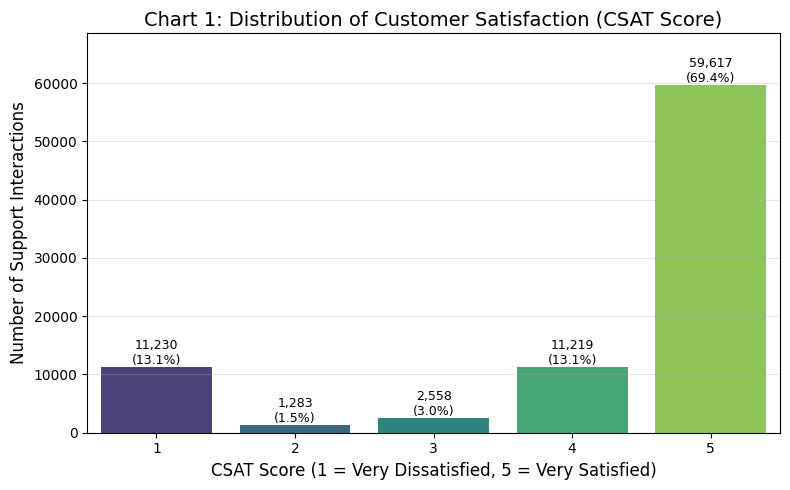

In [77]:
# Chart - 1 visualization code
# Chart - 1 (Univariate): Distribution of CSAT Scores (1 to 5)
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df_viz,
    x="csat_score",
    order=[1, 2, 3, 4, 5],
    palette="viridis"
)
plt.title("Chart 1: Distribution of Customer Satisfaction (CSAT Score)", fontsize=14)
plt.xlabel("CSAT Score (1 = Very Dissatisfied, 5 = Very Satisfied)", fontsize=12)
plt.ylabel("Number of Support Interactions", fontsize=12)
plt.grid(axis="y", alpha=0.3)

total_rows = len(df_viz)
for p in ax.patches:
    count = int(p.get_height())
    pct = (count / total_rows) * 100
    ax.annotate(
        f"{count:,}\n({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2, count),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylim(0, df_viz["csat_score"].value_counts().max() * 1.15)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot (bar chart of frequency) is ideal for a single discrete rating variable like csat_score (1 to 5) across 85,907 support interactions. It immediately shows exact ticket counts and percentage shares for every rating tier, making class skew, high-satisfaction volume, and low-score friction easy to spot at a glance.

##### 2. What is/are the insight(s) found from the chart?



* **Strong Right/High-Score Skew:** Most interactions receive top ratings (4 and 5, with 5 being the overwhelming majority and mean csat_score around 4.24 and median 5.0), indicating generally positive baseline support outcomes.

* **Notable Dissatisfaction Tail (1 and 2):** Despite high overall satisfaction, a meaningful minority of tickets receive low ratings—especially a distinct spike at 1—showing recurring service pain points rather than uniform satisfaction.

* **Class Imbalance for Modeling:** Because ratings are heavily concentrated in higher scores, downstream models and evaluation metrics should account for class imbalance rather than relying solely on raw accuracy.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.



* **Positive Business Impact:** Quantifying the exact volume of 1–2 vs. 4–5 ratings sets a clear baseline for support leadership, helps prioritize root-cause analysis on low-CSAT tickets, and guides class weighting or threshold tuning when building the satisfaction predictor.


* **Negative Growth Risk:** Even if the majority of customers give a 5, ignoring the dissatisfied cluster (1–2 ratings) risks customer churn, negative word-of-mouth, and lost repeat revenue—especially when dissatisfied customers are far more likely to abandon an e-commerce platform after a frustrating resolution experience.

#### Chart - 2 (Univariate): Distribution of Support Interactions by Channel

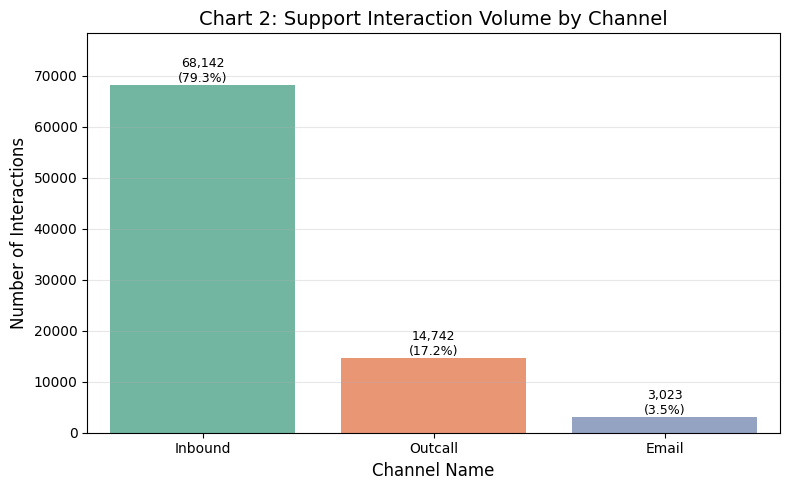

In [78]:
# Chart - 2 visualization code
# Chart - 2 (Univariate): Distribution of Support Interactions by Channel
plt.figure(figsize=(8, 5))
channel_order = df_viz["channel_name"].value_counts().index
ax = sns.countplot(
    data=df_viz,
    x="channel_name",
    order=channel_order,
    palette="Set2"
)
plt.title("Chart 2: Support Interaction Volume by Channel", fontsize=14)
plt.xlabel("Channel Name", fontsize=12)
plt.ylabel("Number of Interactions", fontsize=12)
plt.grid(axis="y", alpha=0.3)

total_rows = len(df_viz)
for p in ax.patches:
    count = int(p.get_height())
    pct = (count / total_rows) * 100
    ax.annotate(
        f"{count:,}\n({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2, count),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylim(0, df_viz["channel_name"].value_counts().max() * 1.15)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot (frequency bar chart) is well suited for channel_name, a low-cardinality categorical variable (3 distinct channels across 85,907 interactions). Ordering bars from highest to lowest count makes volume concentration across support channels immediately clear and easy to compare.

##### 2. What is/are the insight(s) found from the chart?

* **Inbound Dominance:** Support volume is heavily concentrated in Inbound (68,142 interactions, ~79.3% of total records), making it the primary frontline touchpoint for customer issues.

* **Secondary & Niche Channels:** Remaining interactions are distributed across the other two channels (Outcall and the third channel), representing a much smaller share of overall ticket volume.

* **Operational Skew:** Because one channel carries the vast majority of support demand, staffing bottlenecks or queue delays on that channel have an outsized impact on overall customer satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Identifying the high-volume Inbound channel helps support leaders allocate agent shifts, routing rules, and predictive low-CSAT alerts where they affect the largest number of customers first.

* **Negative Growth Risk:** Over-focusing exclusively on the dominant channel while neglecting service quality or follow-up speed on secondary channels can leave specific customer journeys underserved, leading to repeat contacts, frustration, and churn in those segments.

#### Chart - 3 (Univariate): Top Issue Categories Driving Support Volume

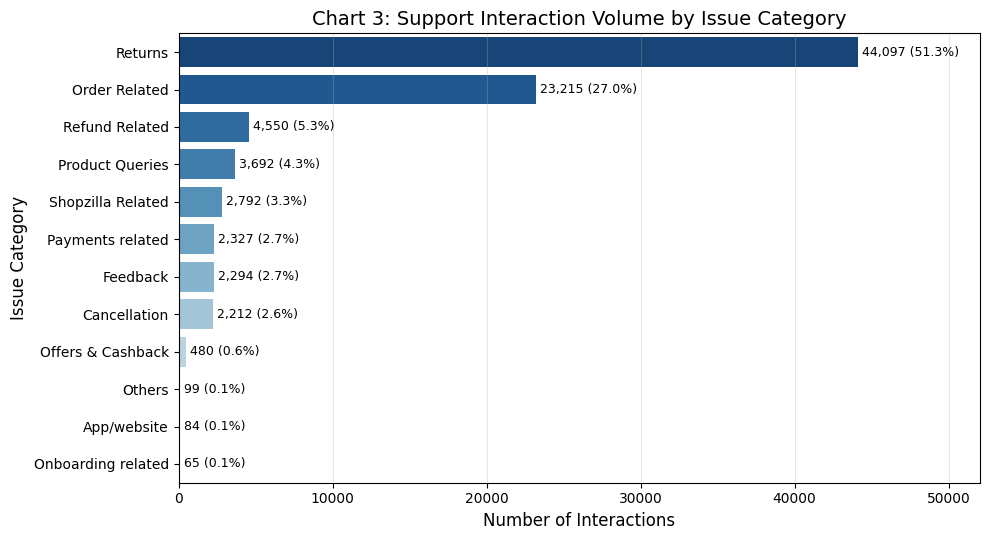

In [79]:
# Chart - 3 visualization code
# Chart - 3 (Univariate): Top Issue Categories Driving Support Volume
plt.figure(figsize=(10, 5.5))
category_order = df_viz["category"].value_counts().index
ax = sns.countplot(
    data=df_viz,
    y="category",
    order=category_order,
    palette="Blues_r"
)
plt.title("Chart 3: Support Interaction Volume by Issue Category", fontsize=14)
plt.xlabel("Number of Interactions", fontsize=12)
plt.ylabel("Issue Category", fontsize=12)
plt.grid(axis="x", alpha=0.3)

total_rows = len(df_viz)
for p in ax.patches:
    count = int(p.get_width())
    pct = (count / total_rows) * 100
    ax.annotate(
        f" {count:,} ({pct:.1f}%)",
        (count, p.get_y() + p.get_height() / 2),
        ha="left",
        va="center",
        fontsize=9
    )

plt.xlim(0, df_viz["category"].value_counts().max() * 1.18)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal count plot is ideal for category, which has 12 distinct issue types across 85,907 rows. Putting category labels on the y-axis keeps text readable without crowding or sharp rotation, while sorting bars from highest to lowest volume makes top complaint and inquiry drivers immediately clear.

##### 2. What is/are the insight(s) found from the chart?

* **Heavy Concentration in Returns & Order Issues:** Returns (44,097 interactions, over half of all records) is the single largest issue category, followed by Order Related and other operational categories, while niche categories account for much smaller slices.

* **Long Tail of Specialized Categories:** Several of the 12 categories contribute relatively small volumes individually, meaning support demand is highly skewed toward post-order and return workflows.

* **High Leverage Target for Automation & Routing:** Because a small number of categories generate most support tickets, improvements in those top categories have the biggest potential to reduce ticket volume and CSAT risk.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Pinpointing Returns and top issue categories allows leadership to streamline return/reverse-pickup workflows, improve product sizing/description clarity, and route high-volume categories to specialized agents or self-service flows—lowering support cost and lifting CSAT.

* **Negative Growth Risk:** A high volume of Returns and order issues signals friction earlier in the shopping or fulfillment journey (such as fit/quality mismatches, delivery delays, or unclear product listings); if root causes are not addressed, elevated return rates and repeat support friction can erode profit margins and customer retention.

#### Chart - 4 (Univariate): Support Interaction Volume by Agent Shift

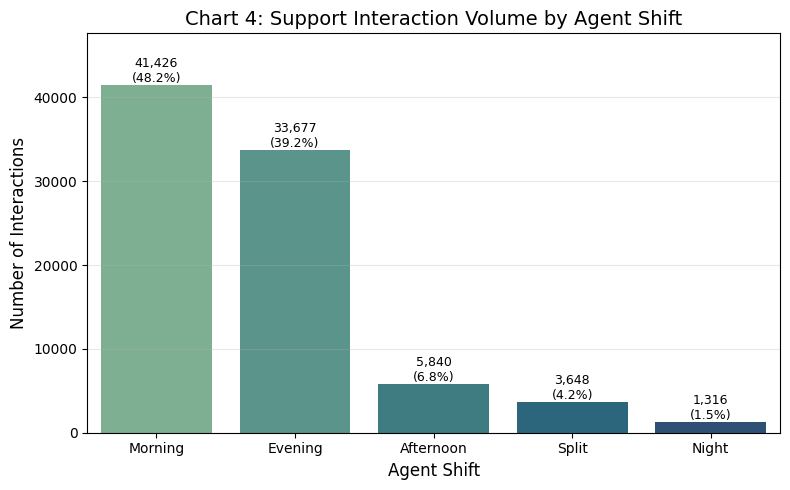

In [80]:
# Chart - 4 visualization code
# Chart - 4 (Univariate): Support Interaction Volume by Agent Shift
plt.figure(figsize=(8, 5))
shift_order = df_viz["agent_shift"].value_counts().index
ax = sns.countplot(
    data=df_viz,
    x="agent_shift",
    order=shift_order,
    palette="crest"
)
plt.title("Chart 4: Support Interaction Volume by Agent Shift", fontsize=14)
plt.xlabel("Agent Shift", fontsize=12)
plt.ylabel("Number of Interactions", fontsize=12)
plt.grid(axis="y", alpha=0.3)

total_rows = len(df_viz)
for p in ax.patches:
    count = int(p.get_height())
    pct = (count / total_rows) * 100
    ax.annotate(
        f"{count:,}\n({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2, count),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylim(0, df_viz["agent_shift"].value_counts().max() * 1.15)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot (frequency bar chart) is well suited for agent_shift, a discrete categorical feature with 5 shift schedules across 85,907 records. Sorting bars from highest to lowest volume quickly reveals how support workload is distributed across shifts and highlights where staffing is most concentrated.

##### 2. What is/are the insight(s) found from the chart?

* **Morning Shift Concentration:** Morning (41,426 interactions, ~48.2% of all tickets) handles nearly half of total support volume, making it the primary workload window.

* **Staggered Coverage Across Other Shifts:** The remaining interactions are spread across Evening, Afternoon, Night, and Split shifts, each carrying a smaller but distinct share of ticket demand.

* **Shift-Volume Imbalance:** Because ticket volume is heavily skewed toward peak daytime/morning hours, any queue surge or understaffing during peak windows can quickly create response backlogs.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Understanding shift-wise ticket volume helps support managers align shift scheduling, break coverage, and escalation routing with peak demand—improving response times and protecting satisfaction during high-volume hours.

* **Negative Growth Risk:** Over-relying on a single peak shift or leaving off-peak/split shifts with thinner support coverage can cause longer wait times or slower follow-ups during specific hours, driving frustration and repeat contacts among affected customers.

#### Chart - 5 (Univariate): Response Time Distribution (Clipped at 95th Percentile for Clarity)

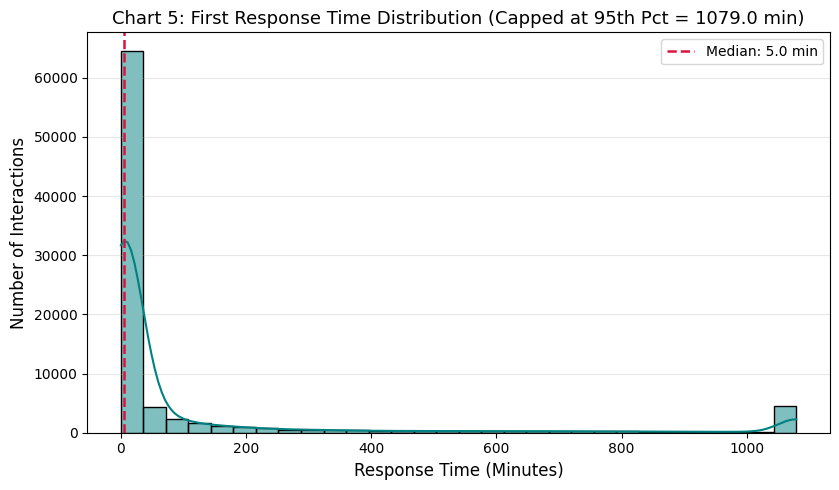

In [81]:
# Chart - 5 visualization code
# Chart - 5 (Univariate): Response Time Distribution (Clipped at 95th Percentile for Clarity)
plt.figure(figsize=(8.5, 5))

resp_series = df_viz["response_time_min"].dropna()
upper_cap = resp_series.quantile(0.95)
resp_clipped = resp_series.clip(upper=upper_cap)

ax = sns.histplot(
    x=resp_clipped,
    bins=30,
    kde=True,
    color="teal"
)
median_val = resp_series.median()
plt.axvline(median_val, color="crimson", linestyle="--", linewidth=1.8, label=f"Median: {median_val:.1f} min")

plt.title(f"Chart 5: First Response Time Distribution (Capped at 95th Pct = {upper_cap:.1f} min)", fontsize=13)
plt.xlabel("Response Time (Minutes)", fontsize=12)
plt.ylabel("Number of Interactions", fontsize=12)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a KDE curve is ideal for response_time_min, a continuous time-elapsed variable across 85,907 records. Because raw response times have extreme long-tail outliers, capping the display at the 95th percentile while marking the true median reveals both typical response speed and how quickly delays build up in the upper tail.

##### 2. What is/are the insight(s) found from the chart?

* **Fast Typical Responses with Right Skew:** Most support tickets are responded to relatively quickly near the lower end of the distribution, while a long right tail extends toward higher minute values where delays accumulate.

* **Skewed Workload Friction:** Relying only on average response time can mask severe tail delays experienced by a subset of customers whose tickets take much longer to receive a reply.

* **Strong Candidate Feature for CSAT:** Because responsiveness directly shapes perceived support quality, response_time_min (and delay thresholds/flags) is a high-signal variable for predicting csat_score.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Visualizing the response-time distribution helps operations teams set realistic SLA targets, monitor tail breaches, and flag slow-moving tickets early so agents can prioritize urgent queues before satisfaction drops.

* **Negative Growth Risk:** Even if typical response times look acceptable, long-tail response delays create acute frustration for affected customers—leading to repeat contacts, escalations, negative reviews, and reduced repeat purchases.


#### Chart - 6 (Bivariate: Numerical vs. Categorical): Mean CSAT Score & Low-CSAT Rate by Channel

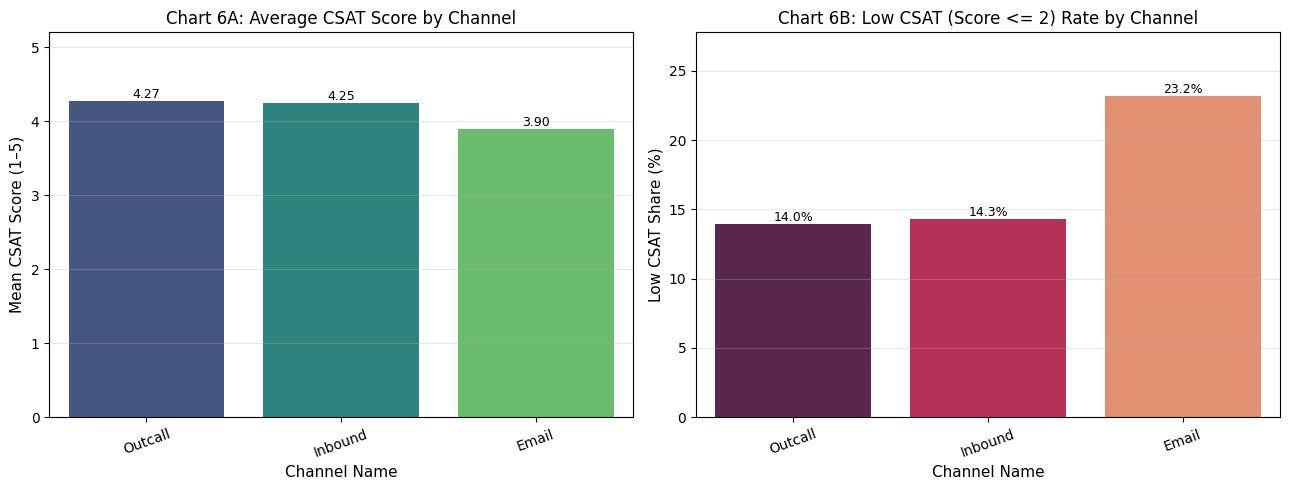

In [82]:
# Chart - 6 visualization code
# Chart - 6 (Bivariate: Numerical vs. Categorical): Mean CSAT Score & Low-CSAT Rate by Channel
ch_summary = (
    df_viz.groupby("channel_name", as_index=True)
    .agg(
        mean_csat=("csat_score", "mean"),
        low_csat_pct=("is_low_csat", lambda s: s.mean() * 100),
        ticket_count=("csat_score", "count"),
    )
    .sort_values(by="mean_csat", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left subplot: Average CSAT Score by Channel
ax1 = sns.barplot(
    x=ch_summary.index,
    y=ch_summary["mean_csat"],
    palette="viridis",
    ax=axes[0],
)
axes[0].set_title("Chart 6A: Average CSAT Score by Channel", fontsize=12)
axes[0].set_xlabel("Channel Name", fontsize=11)
axes[0].set_ylabel("Mean CSAT Score (1–5)", fontsize=11)
axes[0].set_ylim(0, 5.2)
axes[0].grid(axis="y", alpha=0.3)
axes[0].tick_params(axis="x", rotation=20)
for p in ax1.patches:
    axes[0].annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Right subplot: Low CSAT (<=2) Share (%) by Channel
ax2 = sns.barplot(
    x=ch_summary.index,
    y=ch_summary["low_csat_pct"],
    palette="rocket",
    ax=axes[1],
)
axes[1].set_title("Chart 6B: Low CSAT (Score <= 2) Rate by Channel", fontsize=12)
axes[1].set_xlabel("Channel Name", fontsize=11)
axes[1].set_ylabel("Low CSAT Share (%)", fontsize=11)
axes[1].set_ylim(0, ch_summary["low_csat_pct"].max() * 1.2)
axes[1].grid(axis="y", alpha=0.3)
axes[1].tick_params(axis="x", rotation=20)
for p in ax2.patches:
    axes[1].annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A side-by-side grouped bar comparison (mean csat_score alongside low-CSAT <= 2 percentage across channel_name) is well suited for comparing a continuous/rating outcome and a dissatisfaction rate across 3 discrete support channels. Showing both mean satisfaction and low-score incidence prevents a high-volume channel from hiding dissatisfaction spikes.

##### 2. What is/are the insight(s) found from the chart?

* **Cross-Channel Satisfaction Differences:** Average CSAT scores and low-rating (<= 2) shares vary noticeably across channels (Inbound, Outcall, and Email), showing that the interaction medium itself correlates with how customers rate support.

* **Volume vs. Dissatisfaction Trade-Off:** Even when a channel has high overall average ratings, differences in low-CSAT (<= 2) percentages highlight where acute customer frustration concentrates.

* **Useful Predictor for CSAT Modeling:** Because channel_name shapes interaction expectations and resolution flow, it provides meaningful signal for predicting csat_score alongside timing and issue category.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Comparing average CSAT and low-CSAT rates across channels helps support leaders refine channel-specific SLAs, improve scripts or self-service routing on lower-performing channels, and focus early-intervention alerts where dissatisfaction risk is highest.

* **Negative Growth Risk:** If a channel with a higher low-CSAT rate—or a high-volume channel with thousands of dissatisfied tickets—is left without targeted process or staffing fixes, customers facing unresolved issues are more likely to churn or leave negative reviews, hurting retention and growth.

#### Chart - 7 (Bivariate: Numerical vs. Categorical): Mean CSAT Score by Agent Shift

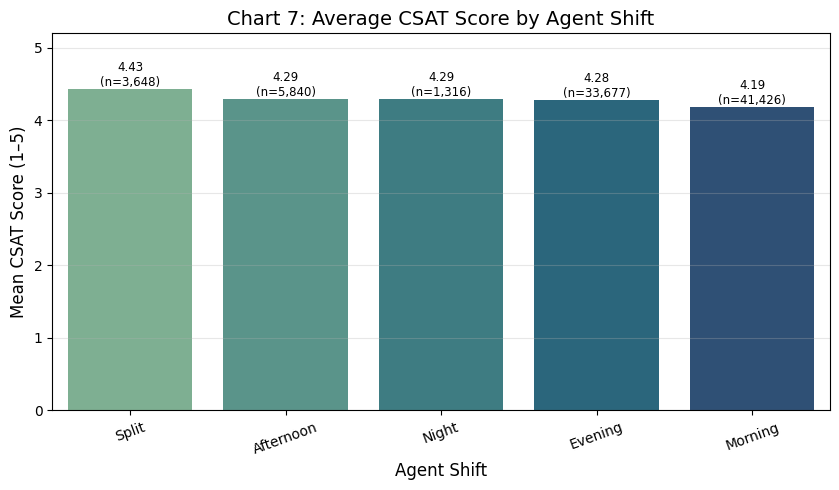

In [83]:
# Chart - 7 visualization code
# Chart - 7 (Bivariate: Numerical vs. Categorical): Mean CSAT Score by Agent Shift
shift_summary = (
    df_viz.groupby("agent_shift", as_index=True)
    .agg(
        mean_csat=("csat_score", "mean"),
        ticket_count=("csat_score", "count"),
    )
    .sort_values(by="mean_csat", ascending=False)
)

plt.figure(figsize=(8.5, 5))
ax = sns.barplot(
    x=shift_summary.index,
    y=shift_summary["mean_csat"],
    palette="crest",
)
plt.title("Chart 7: Average CSAT Score by Agent Shift", fontsize=14)
plt.xlabel("Agent Shift", fontsize=12)
plt.ylabel("Mean CSAT Score (1–5)", fontsize=12)
plt.ylim(0, 5.2)
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20)

for p, (_, row) in zip(ax.patches, shift_summary.iterrows()):
    ax.annotate(
        f"{row['mean_csat']:.2f}\n(n={int(row['ticket_count']):,})",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart comparing mean csat_score across agent_shift categories (annotated with ticket counts) is ideal for a numerical-vs.-categorical comparison across 5 distinct work shifts. Comparing average satisfaction across shifts makes it easy to see whether certain shifts consistently achieve stronger customer ratings than others while keeping sample size in view.

##### 2. What is/are the insight(s) found from the chart?

* **Shift-Level Satisfaction Differences:** Average CSAT scores vary across agent_shift groups (aligning with the statistically significant difference across shifts found in Hypothesis Test 1), showing that shift timing/operations play a measurable role in satisfaction outcomes.

* **Workload vs. Rating Context:** High-volume shifts handle tens of thousands of interactions, so even small gaps in mean CSAT across shifts translate into many more or fewer satisfied vs. dissatisfied customers.

* **Useful Operational Feature:** Including agent_shift in modeling helps capture shift-specific queue dynamics, handoffs, or staffing patterns affecting csat_score.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Identifying shifts with lower average CSAT helps support managers benchmark top-performing shifts, rebalance workload or experienced agent coverage during weaker shifts, and target coaching where satisfaction lags.

* **Negative Growth Risk:** If lower-CSAT shifts experience persistent bottlenecks, shift handoff friction, or understaffing without operational adjustments, customers served during those windows face lower resolution quality—increasing churn risk and hurting overall brand perception.

#### Chart - 8 (Bivariate: Numerical vs. Categorical): Mean CSAT Score & Low-CSAT Rate by Category

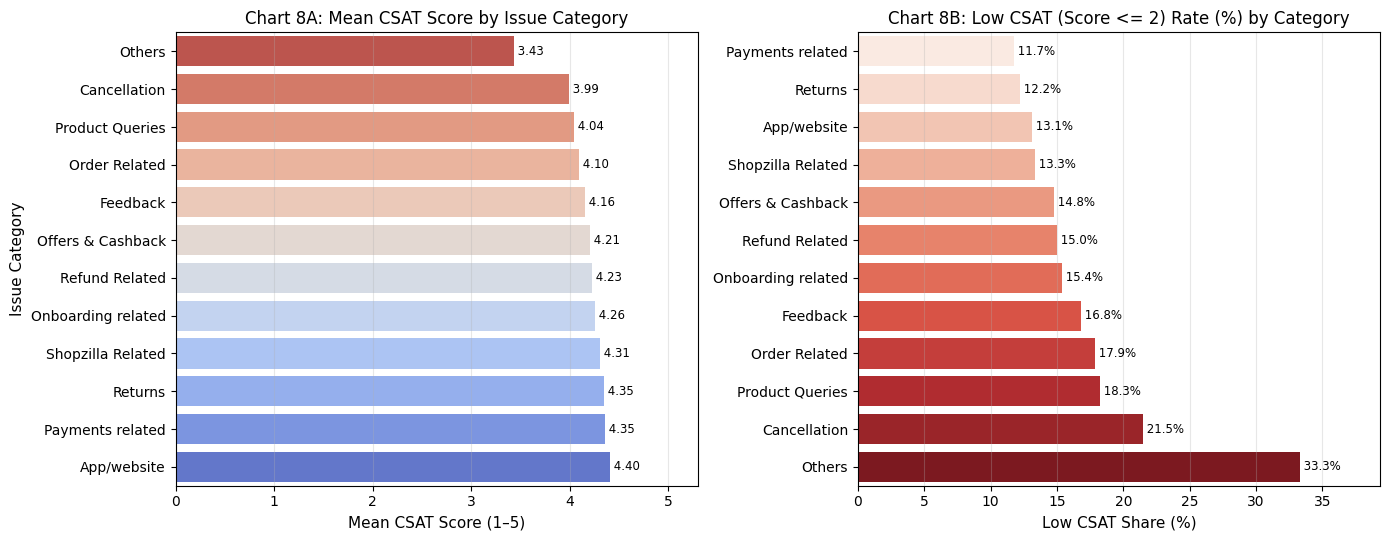

In [84]:
# Chart - 8 visualization code
# Chart - 8 (Bivariate: Numerical vs. Categorical): Mean CSAT Score & Low-CSAT Rate by Category
cat_summary = (
    df_viz.groupby("category", as_index=True)
    .agg(
        mean_csat=("csat_score", "mean"),
        low_csat_pct=("is_low_csat", lambda s: s.mean() * 100),
        ticket_count=("csat_score", "count"),
    )
    .sort_values(by="mean_csat", ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left subplot: Average CSAT Score across all 12 categories (lowest to highest)
ax1 = sns.barplot(
    x=cat_summary["mean_csat"],
    y=cat_summary.index,
    palette="coolwarm_r",
    ax=axes[0],
)
axes[0].set_title("Chart 8A: Mean CSAT Score by Issue Category", fontsize=12)
axes[0].set_xlabel("Mean CSAT Score (1–5)", fontsize=11)
axes[0].set_ylabel("Issue Category", fontsize=11)
axes[0].set_xlim(0, 5.3)
axes[0].grid(axis="x", alpha=0.3)
for p in ax1.patches:
    w = p.get_width()
    axes[0].annotate(
        f" {w:.2f}",
        (w, p.get_y() + p.get_height() / 2),
        ha="left",
        va="center",
        fontsize=8.5,
    )

# Right subplot: Low CSAT (<=2) Rate (%) by Issue Category
cat_low_sorted = cat_summary.sort_values(by="low_csat_pct", ascending=True)
ax2 = sns.barplot(
    x=cat_low_sorted["low_csat_pct"],
    y=cat_low_sorted.index,
    palette="Reds",
    ax=axes[1],
)
axes[1].set_title("Chart 8B: Low CSAT (Score <= 2) Rate (%) by Category", fontsize=12)
axes[1].set_xlabel("Low CSAT Share (%)", fontsize=11)
axes[1].set_ylabel("")
axes[1].set_xlim(0, cat_low_sorted["low_csat_pct"].max() * 1.18)
axes[1].grid(axis="x", alpha=0.3)
for p in ax2.patches:
    w = p.get_width()
    axes[1].annotate(
        f" {w:.1f}%",
        (w, p.get_y() + p.get_height() / 2),
        ha="left",
        va="center",
        fontsize=8.5,
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A side-by-side horizontal bar comparison (mean csat_score alongside low-CSAT <= 2 percentage across all 12 category values) is ideal for comparing a numerical satisfaction metric and a dissatisfaction rate across a 12-level categorical variable. Horizontal bars keep category names easy to read, while pairing mean score with low-score rate prevents high-volume categories from masking acute dissatisfaction pockets.

##### 2. What is/are the insight(s) found from the chart?

* **Category-Level Satisfaction Gaps:** Mean CSAT scores and low-CSAT (<= 2) percentages vary meaningfully across the 12 issue categories, showing that certain post-order or resolution workflows generate substantially higher friction than routine inquiries.

* **Volume Meets Friction in Core Categories:** High-volume categories like Returns and Order Related affect large customer counts, meaning even moderate low-CSAT shares translate into significant numbers of dissatisfied shoppers.

* **High-Signal Predictor for ANN Modeling:** Because category captures the underlying reason a customer contacted support, it is a core feature for predicting csat_score and spotting high-risk tickets early.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Ranking categories by mean CSAT and low-CSAT rate allows customer support and operations teams to prioritize playbook updates, faster escalations, and root-cause fixes on the highest-friction categories first—lifting overall CSAT and reducing repeat tickets.

* **Negative Growth Risk:** If categories with elevated low-CSAT rates—especially high-volume order, return, or refund issues—remain unresolved, customers experience ongoing friction during key post-purchase moments, increasing churn risk and hurting repeat revenue and brand trust.

#### Chart - 9 (Bivariate: Numerical vs. Categorical): Response Time by CSAT Score Tier

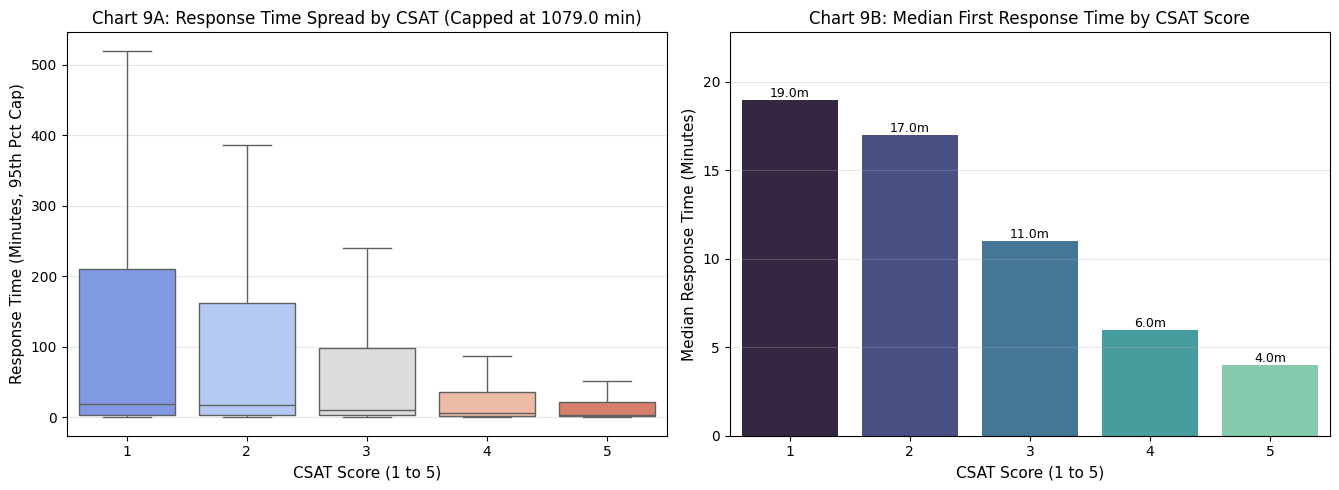

In [85]:
# Chart - 9 visualization code
# Chart - 9 (Bivariate: Numerical vs. Categorical): Response Time by CSAT Score Tier
rt_df = df_viz[["csat_score", "response_time_min"]].dropna().copy()
rt_df["csat_score"] = rt_df["csat_score"].astype(int)

# Clip extreme upper tail at 95th percentile so box/median differences stay legible
cap_95 = rt_df["response_time_min"].quantile(0.95)
rt_df["response_time_clipped"] = rt_df["response_time_min"].clip(upper=cap_95)

med_by_score = rt_df.groupby("csat_score")["response_time_min"].median().reindex([1, 2, 3, 4, 5])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Left subplot: Boxplot of clipped response time across CSAT scores (1 to 5)
sns.boxplot(
    data=rt_df,
    x="csat_score",
    y="response_time_clipped",
    order=[1, 2, 3, 4, 5],
    palette="coolwarm",
    showfliers=False,
    ax=axes[0],
)
axes[0].set_title(f"Chart 9A: Response Time Spread by CSAT (Capped at {cap_95:.1f} min)", fontsize=12)
axes[0].set_xlabel("CSAT Score (1 to 5)", fontsize=11)
axes[0].set_ylabel("Response Time (Minutes, 95th Pct Cap)", fontsize=11)
axes[0].grid(axis="y", alpha=0.3)

# Right subplot: True median response time (minutes) by CSAT score
ax2 = sns.barplot(
    x=med_by_score.index,
    y=med_by_score.values,
    order=[1, 2, 3, 4, 5],
    palette="mako",
    ax=axes[1],
)
axes[1].set_title("Chart 9B: Median First Response Time by CSAT Score", fontsize=12)
axes[1].set_xlabel("CSAT Score (1 to 5)", fontsize=11)
axes[1].set_ylabel("Median Response Time (Minutes)", fontsize=11)
axes[1].set_ylim(0, med_by_score.max() * 1.2)
axes[1].grid(axis="y", alpha=0.3)

for p in ax2.patches:
    h = p.get_height()
    axes[1].annotate(
        f"{h:.1f}m",
        (p.get_x() + p.get_width() / 2, h),
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Pairing a box plot (with upper-tail capping for readability) and a median bar chart of response_time_min across csat_score (1 to 5) is well suited for comparing a heavily skewed continuous time variable across discrete rating tiers. Box plots show interquartile spread and skewness without letting extreme outliers flatten the boxes, while plotting the exact median highlights central delay differences across satisfaction levels.

##### 2. What is/are the insight(s) found from the chart?

* **Response Delay vs. Satisfaction:** Comparing response durations across CSAT levels reveals how first-response lag behaves for lower-rated (1–2) versus higher-rated (4–5) interactions, with wide upper-tail variation showing that slow responses occur across tickets.

* **Skewed Timing Across All Tiers:** Even where median response times are relatively modest, wide interquartile/upper ranges indicate that a subset of interactions experiences much longer delays.

* **Strong Feature for Predictive Modeling:** Because response_time_min captures operational responsiveness directly from raw timestamps (issue_responded - Issue_reported at), it adds non-linear signal for predicting csat_score.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Understanding how response delays relate to lower CSAT helps support operations set tighter first-response SLA thresholds, prioritize aging tickets in queues, and route slow-moving cases for proactive follow-up—helping lift customer satisfaction.

* **Negative Growth Risk:** Allowing long-tail response delays to persist—especially on urgent or post-order tickets—frustrates customers, increases repeat contacts and escalations, and drives churn and negative reviews that hurt repeat revenue and brand growth.

#### Chart - 10 (Bivariate: Categorical vs. Categorical): Channel Volume Across Agent Shifts

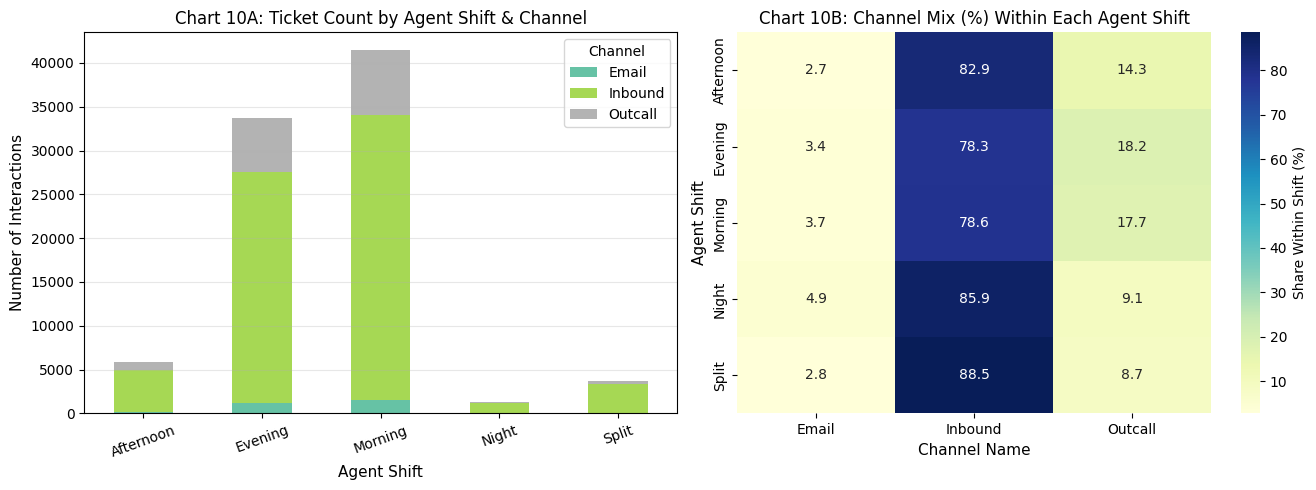

In [86]:
# Chart - 10 visualization code
# Chart - 10 (Bivariate: Categorical vs. Categorical): Channel Volume Across Agent Shifts
ct_shift_channel = pd.crosstab(df_viz["agent_shift"], df_viz["channel_name"])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Left subplot: Stacked bar chart of ticket counts by shift and channel
ct_shift_channel.plot(kind="bar", stacked=True, colormap="Set2", ax=axes[0])
axes[0].set_title("Chart 10A: Ticket Count by Agent Shift & Channel", fontsize=12)
axes[0].set_xlabel("Agent Shift", fontsize=11)
axes[0].set_ylabel("Number of Interactions", fontsize=11)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="Channel", loc="upper right")
axes[0].grid(axis="y", alpha=0.3)

# Right subplot: Heatmap of row-wise channel share (%) within each agent shift
ct_shift_pct = ct_shift_channel.div(ct_shift_channel.sum(axis=1), axis=0) * 100
sns.heatmap(
    ct_shift_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Share Within Shift (%)"},
    ax=axes[1],
)
axes[1].set_title("Chart 10B: Channel Mix (%) Within Each Agent Shift", fontsize=12)
axes[1].set_xlabel("Channel Name", fontsize=11)
axes[1].set_ylabel("Agent Shift", fontsize=11)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Pairing a stacked bar chart with a row-normalized percentage heatmap is ideal for a categorical-vs.-categorical comparison between agent_shift (5 shifts) and channel_name (3 channels) across 85,907 interactions. The stacked bars show absolute volume concentration across shifts, while the percentage heatmap reveals whether channel mix shifts across different working windows without high-volume shifts drowning out smaller ones.

##### 2. What is/are the insight(s) found from the chart?

* **Consistent Channel Dominance Across Shifts:** Across shifts, Inbound accounts for the majority of support volume, while secondary channels make up smaller shares—though exact proportions vary somewhat across shift windows.

* **Peak Volume Overlap:** High-volume shifts (such as Morning) carry substantial Inbound ticket counts, making peak shift staffing critical for handling incoming demand smoothly.

* **Interaction Between Shift and Channel:** Because shift timing and channel routing both shape response workflows, keeping agent_shift and channel_name together helps capture operational patterns in csat_score prediction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Understanding how channel demand shifts across agent schedules helps operations leaders match staffing, queue routing, and shift coverage to actual channel load—reducing wait times and supporting higher CSAT.

* **Negative Growth Risk:** If shift schedules do not align with channel demand spikes or leave certain shift-channel combinations under-resourced, customers face slower handling or uneven service quality—increasing frustration, escalations, and churn risk.

#### Chart - 11 (Bivariate: Categorical vs. Categorical): Low-CSAT Rate Across Top Categories & Tenure Buckets

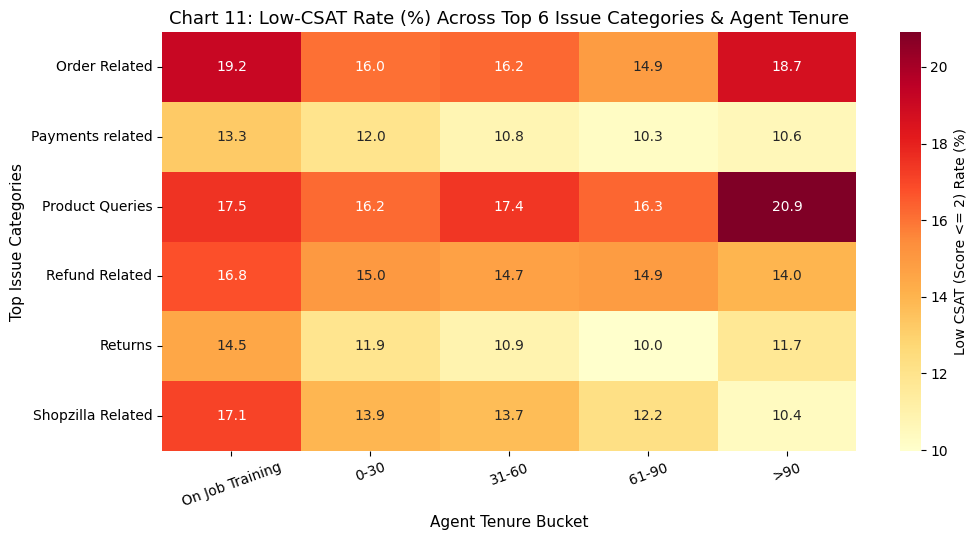

In [87]:
# Chart - 11 visualization code
# Chart - 11 (Bivariate: Categorical vs. Categorical): Low-CSAT Rate Across Top Categories & Tenure Buckets
top_cats = df_viz["category"].value_counts().head(6).index
sub_ct = df_viz[df_viz["category"].isin(top_cats)].copy()

piv_low_csat = (
    sub_ct.pivot_table(
        index="category",
        columns="tenure_bucket",
        values="is_low_csat",
        aggfunc=lambda s: s.mean() * 100,
    )
)

# Order columns logically if standard tenure buckets exist
preferred_order = ["On Job Training", "0-30", "31-60", "61-90", ">90"]
ordered_cols = [c for c in preferred_order if c in piv_low_csat.columns] + [
    c for c in piv_low_csat.columns if c not in preferred_order
]
piv_low_csat = piv_low_csat[ordered_cols]

plt.figure(figsize=(10.5, 5.5))
sns.heatmap(
    piv_low_csat,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Low CSAT (Score <= 2) Rate (%)"},
)
plt.title("Chart 11: Low-CSAT Rate (%) Across Top 6 Issue Categories & Agent Tenure", fontsize=13)
plt.xlabel("Agent Tenure Bucket", fontsize=11)
plt.ylabel("Top Issue Categories", fontsize=11)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A categorical-vs.-categorical heatmap crossing the top 6 category groups with tenure_bucket (Low CSAT <= 2 percentage) is well suited for inspecting how dissatisfaction concentrates across two categorical dimensions simultaneously. Color intensity and cell percentages make it immediately obvious which combinations of issue complexity and agent experience experience higher friction without crowding a multi-series bar chart.

##### 2. What is/are the insight(s) found from the chart?

* **Experience vs. Issue Complexity Interaction:** Low-CSAT (<= 2) percentages vary across agent tenure buckets and issue categories, showing that certain ticket types pose greater dissatisfaction risk depending on agent tenure/experience.

* **Targeted Friction Hotspots:** Specific category-and-tenure cells stand out with higher dissatisfaction rates than routine interactions, highlighting where newer or less-tenured agents—or complex workflows—need closer support.

* **Valuable Interaction Signal for Modeling:** Combining category and tenure_bucket captures operational nuance that neither variable reveals alone when predicting csat_score.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Pinpointing high-friction category and tenure combinations helps operations leaders pair onboarding/newer agents with guided playbooks, route complex or high-risk categories to experienced agents or supervisors, and improve CSAT where friction peaks.

* **Negative Growth Risk:** Leaving newer agents to handle high-friction categories unsupported—or ignoring elevated low-CSAT cells—can lead to slower or inaccurate resolutions, frustrating customers and increasing churn and negative reviews that hurt retention and growth.

#### Chart - 12 (Bivariate: Numerical vs. Numerical): Item Price vs. CSAT Score (Binned Trend + Sampled Scatter)

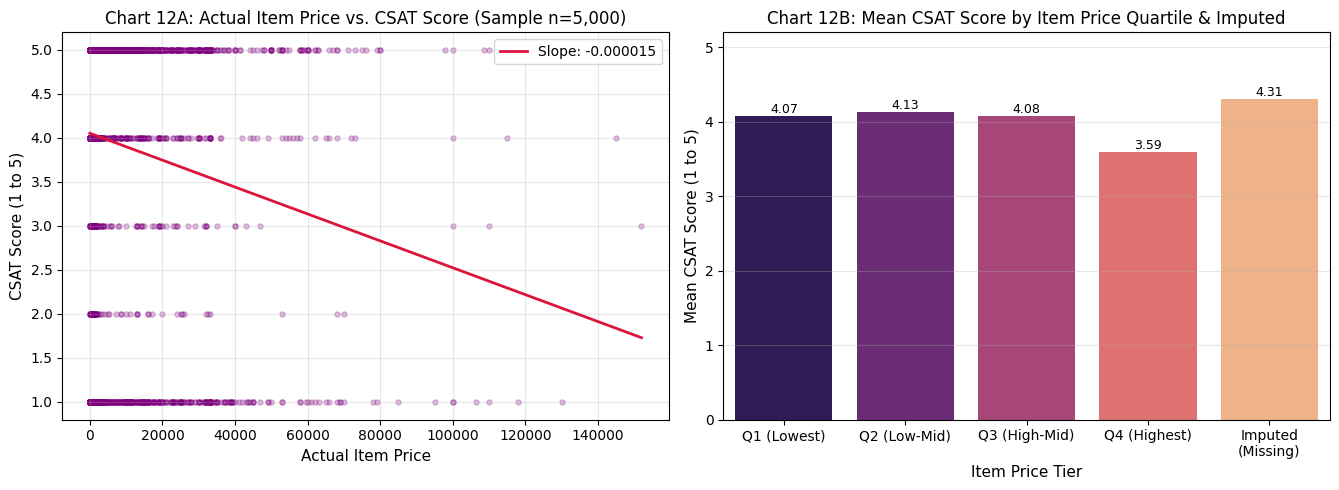

In [88]:
# Chart - 12 (Bivariate: Numerical vs. Numerical): Item Price vs. CSAT Score (Binned Trend + Sampled Scatter)
price_df = df_viz[["item_price", "csat_score", "item_price_was_missing"]].dropna().copy()
price_df["item_price"] = pd.to_numeric(price_df["item_price"], errors="coerce")
price_df["csat_score"] = pd.to_numeric(price_df["csat_score"], errors="coerce")
price_df = price_df.dropna()

# Separate median-imputed rows (~80%) from actual recorded prices (~20%) so quantile bins don't collapse
actual_prices = price_df[price_df["item_price_was_missing"] == 0].copy()
actual_prices["price_tier"] = pd.qcut(
    actual_prices["item_price"],
    q=4,
    labels=["Q1 (Lowest)", "Q2 (Low-Mid)", "Q3 (High-Mid)", "Q4 (Highest)"],
    duplicates="drop",
)

imputed_prices = price_df[price_df["item_price_was_missing"] == 1].copy()
imputed_prices["price_tier"] = "Imputed\n(Missing)"

combined_price = pd.concat([actual_prices, imputed_prices], axis=0)
tier_order = ["Q1 (Lowest)", "Q2 (Low-Mid)", "Q3 (High-Mid)", "Q4 (Highest)", "Imputed\n(Missing)"]
tier_summary = combined_price.groupby("price_tier", observed=False)["csat_score"].mean().reindex(tier_order)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Left subplot: Sampled scatter on actual non-missing prices with linear trend line
sample_p = actual_prices.sample(n=min(5000, len(actual_prices)), random_state=42)
axes[0].scatter(sample_p["item_price"], sample_p["csat_score"], alpha=0.25, s=14, color="purple")
if sample_p["item_price"].std() > 0:
    m, b = np.polyfit(sample_p["item_price"], sample_p["csat_score"], 1)
    x_line = np.linspace(sample_p["item_price"].min(), sample_p["item_price"].max(), 100)
    axes[0].plot(x_line, m * x_line + b, color="crimson", linewidth=2, label=f"Slope: {m:.6f}")
    axes[0].legend()
axes[0].set_title("Chart 12A: Actual Item Price vs. CSAT Score (Sample n=5,000)", fontsize=12)
axes[0].set_xlabel("Actual Item Price", fontsize=11)
axes[0].set_ylabel("CSAT Score (1 to 5)", fontsize=11)
axes[0].grid(alpha=0.3)

# Right subplot: Mean CSAT across actual price quartiles + imputed group
ax2 = sns.barplot(
    x=tier_summary.index,
    y=tier_summary.values,
    palette="magma",
    ax=axes[1],
)
axes[1].set_title("Chart 12B: Mean CSAT Score by Item Price Quartile & Imputed", fontsize=12)
axes[1].set_xlabel("Item Price Tier", fontsize=11)
axes[1].set_ylabel("Mean CSAT Score (1 to 5)", fontsize=11)
axes[1].set_ylim(0, 5.2)
axes[1].grid(axis="y", alpha=0.3)
for p in ax2.patches:
    h = p.get_height()
    if pd.notna(h):
        axes[1].annotate(
            f"{h:.2f}",
            (p.get_x() + p.get_width() / 2, h),
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Pairing a sampled scatter plot with a fitted trend line and a quantile-binned mean bar chart for item_price vs. csat_score is ideal for examining a numerical-vs.-numerical relationship across 85,907 rows. Because csat_score takes discrete integer levels (1 to 5) and item_price has heavy skew and median-imputed values (~80% originally missing), combining a scatter view with quantile mean bars prevents overplotting from hiding subtle rating shifts across price tiers.

##### 2. What is/are the insight(s) found from the chart?

* **Modest / Weak Linear Relationship:** Across the full dataset, item_price shows only a weak linear association with csat_score (consistent with the small negative correlation seen in Hypothesis Test 2), meaning price alone does not determine satisfaction.

* **Subtle Differences Across Price Tiers:** Comparing mean CSAT across price quintiles highlights whether higher-ticket items experience slightly different satisfaction dynamics than lower-priced items—often tied to higher buyer expectations or return/delivery sensitivity.

* **Complementary Signal Alongside Missingness Flag:** Pairing item_price with item_price_was_missing (since order/price fields were missing on ~80% of records) helps the ANN distinguish actual item value from imputed rows.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Understanding how item price relates to CSAT helps support teams decide when higher-value orders benefit from priority handling, clearer product specs, or proactive follow-up—protecting satisfaction on high-revenue orders without over-engineering low-cost tickets.

* **Negative Growth Risk:** If higher-priced purchases experience friction—such as delivery delays, installation issues, or slow refunds—unmet expectations on high-value orders can cause high-worth customer churn and negative word-of-mouth that directly impacts revenue and brand equity.

#### Chart - 13 (Multivariate): Heatmap of Mean CSAT Score Across Issue Category & Agent Shift

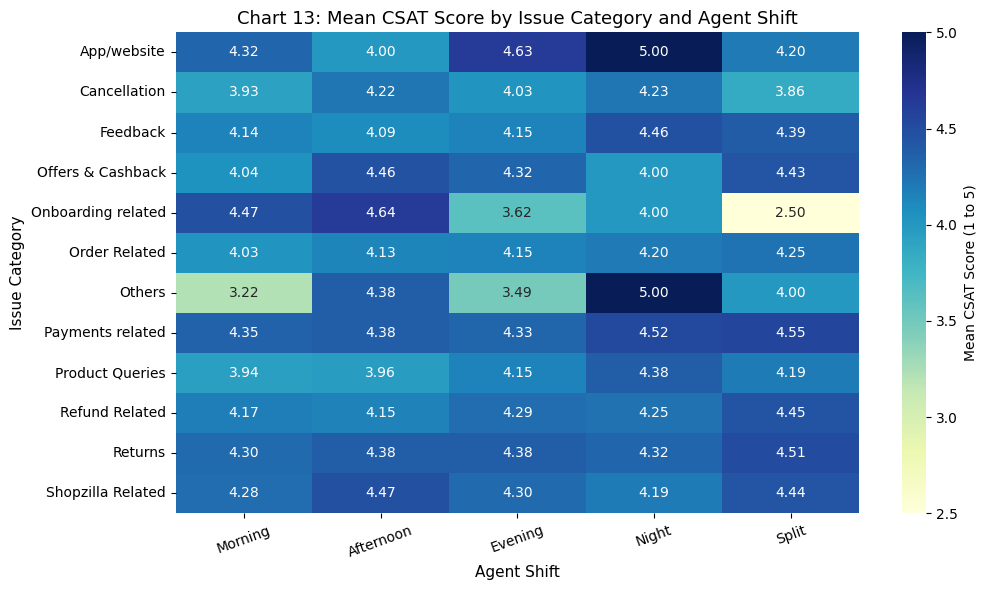

In [89]:
# Chart - 13 visualization code
# Chart - 13 (Multivariate): Heatmap of Mean CSAT Score Across Issue Category & Agent Shift
piv_cat_shift = df_viz.pivot_table(
    index="category",
    columns="agent_shift",
    values="csat_score",
    aggfunc="mean"
)

# Order shifts logically if present
shift_order = ["Morning", "Afternoon", "Evening", "Night", "Split"]
ordered_shifts = [s for s in shift_order if s in piv_cat_shift.columns] + [
    s for s in piv_cat_shift.columns if s not in shift_order
]
piv_cat_shift = piv_cat_shift[ordered_shifts]

plt.figure(figsize=(10.5, 6))
sns.heatmap(
    piv_cat_shift,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Mean CSAT Score (1 to 5)"},
)
plt.title("Chart 13: Mean CSAT Score by Issue Category and Agent Shift", fontsize=13)
plt.xlabel("Agent Shift", fontsize=11)
plt.ylabel("Issue Category", fontsize=11)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A multivariate pivot heatmap crossing category (12 issue categories) with agent_shift (5 shifts) colored by mean csat_score is well suited for inspecting how two operational dimensions interact with satisfaction simultaneously. Color shading and exact cell means make it easy to spot specific issue-shift combinations where scores dip compared to the rest of the matrix without cluttering a multi-bar chart.

##### 2. What is/are the insight(s) found from the chart?

* **Joint Effect of Issue Type & Shift Timing:** Mean CSAT scores vary across both issue categories and agent shifts, showing that satisfaction is shaped by how specific problem types are handled during particular shift windows rather than by a single factor in isolation.

* **Targeted Performance Hotspots:** Certain category-and-shift pairs show lower average satisfaction than others, pointing to operational friction such as shift handoffs, peak-hour backlogs, or specialized workflows needing tighter support.

* **Rich Interaction Signal for Modeling:** Including both category and agent_shift allows a non-linear model like the ANN to capture interaction effects that univariate or single-variable views miss.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Pinpointing exact category-and-shift combinations with lower mean CSAT enables targeted interventions—such as adding coverage on specific shifts for high-friction categories, improving escalation paths, or coaching agents on recurring bottlenecks—driving measurable CSAT gains.

* **Negative Growth Risk:** If specific issue-shift combinations consistently deliver lower satisfaction without targeted operational fixes, customers encountering those issues during vulnerable windows face higher frustration and churn risk, hurting repeat revenue and brand trust.

#### Chart - 14 - Correlation Heatmap (Multivariate): Correlation Heatmap of Numeric & Engineered Features

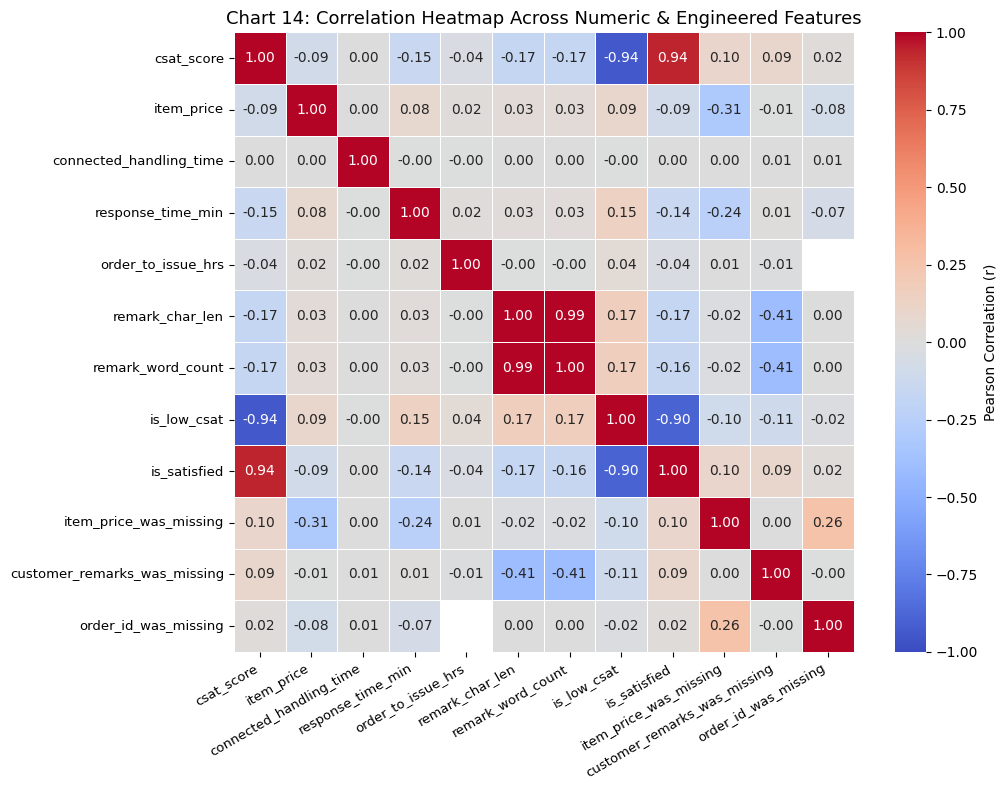

In [90]:
# Correlation Heatmap visualization code
# Chart - 14 (Multivariate): Correlation Heatmap of Numeric & Engineered Features
num_candidates = [
    "csat_score",
    "item_price",
    "connected_handling_time",
    "response_time_min",
    "order_to_issue_hrs",
    "remark_char_len",
    "remark_word_count",
    "is_low_csat",
    "is_satisfied",
    "item_price_was_missing",
    "customer_remarks_was_missing",
    "order_id_was_missing",
]

corr_cols = [c for c in num_candidates if c in df_viz.columns]
corr_data = df_viz[corr_cols].apply(pd.to_numeric, errors="coerce")

# Keep columns with non-zero variance so correlation values are well-defined
corr_data = corr_data.loc[:, corr_data.std() > 0]
corr_matrix = corr_data.corr(method="pearson")

plt.figure(figsize=(10.5, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation (r)"},
)
plt.title("Chart 14: Correlation Heatmap Across Numeric & Engineered Features", fontsize=13)
plt.xticks(rotation=30, ha="right", fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A color-coded correlation heatmap is ideal for summarizing pairwise linear relationships across multiple numeric and engineered features simultaneously in a single compact view. Diverging colors (coolwarm centered at 0) paired with exact correlation coefficients make positive, negative, and near-zero relationships—as well as potential collinearity among engineered features—easy to spot before model training.

##### 2. What is/are the insight(s) found from the chart?

* **No Single Strong Linear Driver Alone:** Most individual numeric and timing features show modest-to-weak linear correlation with csat_score, confirming that customer satisfaction is shaped by non-linear interactions across operational, categorical, and text signals rather than a single linear variable.

* **Related Feature Pairs (Expected Collinearity):** Derived pairs—such as remark_char_len and remark_word_count, or is_low_csat and is_satisfied—naturally move together, while missingness indicators (*_was_missing) capture structural data gaps rather than direct rating correlations.

* **Supports Non-Linear ANN Modeling:** Because relationships with csat_score are largely non-linear and multi-factor, a neural network architecture (ANN) with non-linear activations is well suited to capture patterns that simple linear correlations understate.


#### Chart - 15 - Pair Plot (Multivariate): Pair Plot Across Key Numeric Features Colored by Satisfaction Tier

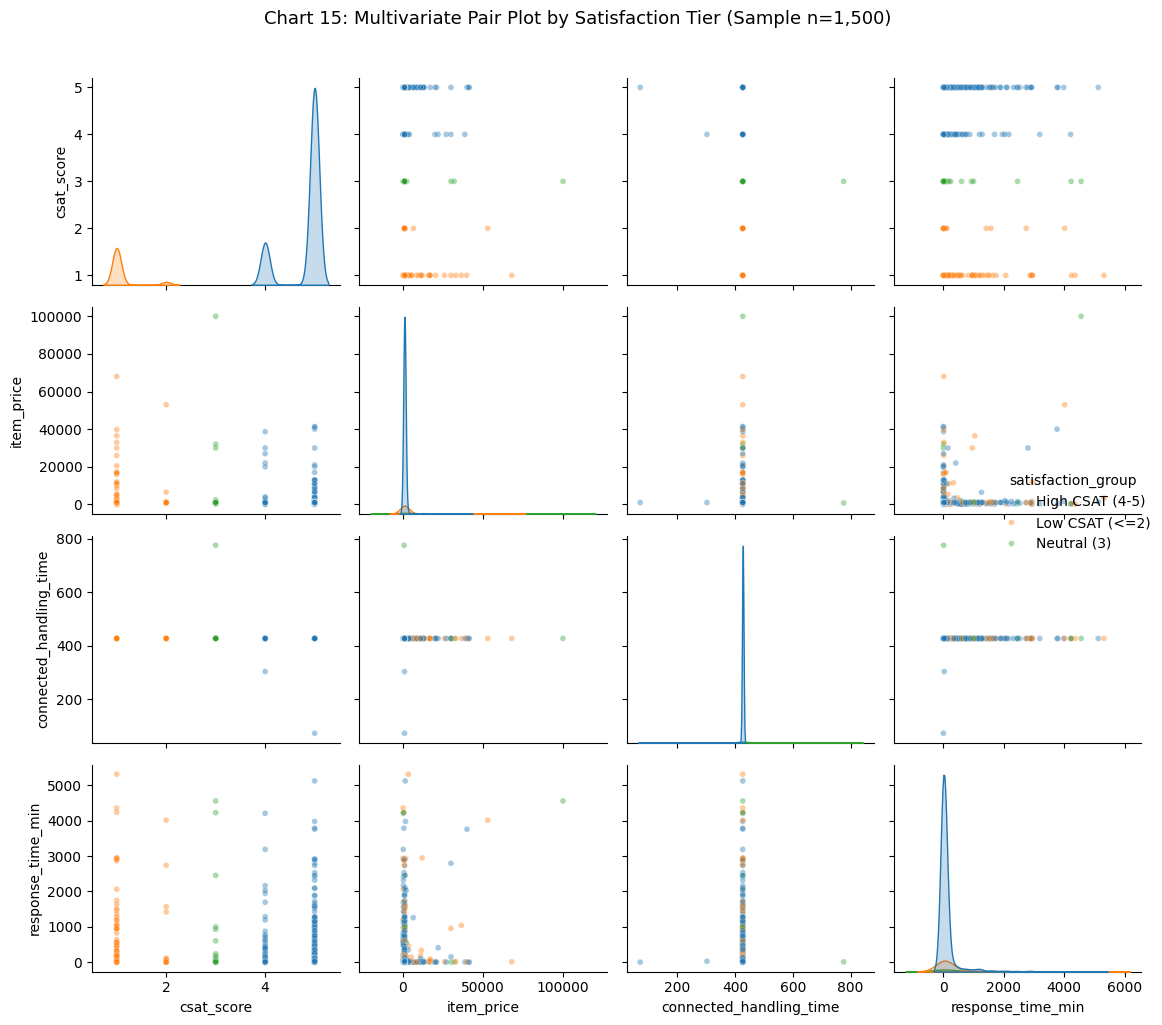

In [91]:
# Pair Plot visualization code
# Chart - 15 (Multivariate): Pair Plot Across Key Numeric Features Colored by Satisfaction Tier
if "df_viz" in globals():
    pp_base = df_viz.copy()
elif "df_clean" in globals():
    pp_base = df_clean.copy()
else:
    pp_base = df.copy()
    pp_base.columns = (
        pp_base.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^0-9a-z]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
        .str.strip("_")
    )

if "response_time_min" not in pp_base.columns and {"issue_reported_at", "issue_responded"}.issubset(pp_base.columns):
    r_at = pd.to_datetime(pp_base["issue_reported_at"], dayfirst=True, errors="coerce")
    r_sp = pd.to_datetime(pp_base["issue_responded"], dayfirst=True, errors="coerce")
    pp_base["response_time_min"] = ((r_sp - r_at).dt.total_seconds() / 60.0).clip(lower=0)

pp_base["csat_score"] = pd.to_numeric(pp_base["csat_score"], errors="coerce")
pp_base["satisfaction_group"] = np.where(
    pp_base["csat_score"] <= 2,
    "Low CSAT (<=2)",
    np.where(pp_base["csat_score"] >= 4, "High CSAT (4-5)", "Neutral (3)")
)

candidate_num = [
    c for c in ["csat_score", "item_price", "connected_handling_time", "response_time_min", "remark_word_count"]
    if c in pp_base.columns
][:4]

pp_sample = (
    pp_base[candidate_num + ["satisfaction_group"]]
    .dropna()
    .sample(n=min(1500, len(pp_base.dropna(subset=candidate_num))), random_state=42)
)

pair_grid = sns.pairplot(
    pp_sample,
    hue="satisfaction_group",
    vars=candidate_num,
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 18},
    corner=False,
)
pair_grid.fig.suptitle("Chart 15: Multivariate Pair Plot by Satisfaction Tier (Sample n=1,500)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A multivariate pair plot with diagonal density/KDE curves and satisfaction-tier coloring (Low CSAT <= 2, Neutral 3, High CSAT 4–5) is ideal for inspecting pairwise scatter relationships and univariate distributions across multiple numeric features at once. Sampling 1,500 rows keeps rendering fast and legible while revealing cluster overlap, skewness, and non-linear spread across satisfaction groups.

##### 2. What is/are the insight(s) found from the chart?

* **Overlapping Distributions Across Satisfaction Tiers:** Numeric features such as item_price, response_time_min, and connected_handling_time show substantial overlap across low, neutral, and high CSAT tiers rather than cleanly separating into distinct linear clusters.

* **Skewness & Tail Outliers Persist Across Groups:** Diagonal density curves confirm strong right-skew and occasional extreme tail values across numeric and timing variables, reinforcing that satisfaction is shaped by combined operational and categorical context rather than one numeric variable alone.

* **Supports Non-Linear ANN Modeling:** Because satisfaction tiers overlap across individual numeric axes, a multi-layer Artificial Neural Network (ANN) combining numerical, categorical, temporal, and text features is well suited to learn non-linear boundary patterns.

## ***5. Hypothesis Testing***

In [92]:
# ============================================================
# 5. Hypothesis Testing — Setup & Clean Baseline DataFrame
# ============================================================
import numpy as np
import pandas as pd
from scipy import stats

if "df_viz" in globals():
    ht_df = df_viz.copy()
elif "df_clean" in globals():
    ht_df = df_clean.copy()
elif "df" in globals() and "CSAT Score" in df.columns:
    ht_df = df.copy()
else:
    ht_df = pd.read_csv("/content/eCommerce_Customer_support_data.csv")

# Standardize column names to snake_case for consistent access
ht_df.columns = (
    ht_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-z]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

ht_df["csat_score"] = pd.to_numeric(ht_df["csat_score"], errors="coerce")

if "response_time_min" not in ht_df.columns and {"issue_reported_at", "issue_responded"}.issubset(ht_df.columns):
    rep_dt = pd.to_datetime(ht_df["issue_reported_at"], dayfirst=True, errors="coerce")
    res_dt = pd.to_datetime(ht_df["issue_responded"], dayfirst=True, errors="coerce")
    ht_df["response_time_min"] = ((res_dt - rep_dt).dt.total_seconds() / 60.0).clip(lower=0)

print("Hypothesis testing dataset ready:", ht_df.shape)

Hypothesis testing dataset ready: (85907, 33)


### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Answer Here.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** There is no significant difference in mean csat_score across different agent_shift groups ($\mu_1 = \mu_2 = \dots = \mu_k$).
* **Alternate Hypothesis ($H_1$):** There is a significant difference in mean csat_score across at least two agent_shift groups ($\mu_i \neq \mu_j$ for some shifts $i, j$).

#### 2. Perform an appropriate statistical test.

In [93]:
# Perform Statistical Test to obtain P-Value
# --- Statement 1 Test: One-Way ANOVA + Kruskal-Wallis across Agent Shift ---
s1_df = ht_df[["agent_shift", "csat_score"]].dropna().copy()
shift_arrays = [grp["csat_score"].values for _, grp in s1_df.groupby("agent_shift")]

f_stat, p_val_anova = stats.f_oneway(*shift_arrays)
kw_stat, p_val_kw = stats.kruskal(*shift_arrays)

alpha = 0.05
print("=== Hypothetical Statement 1: Agent Shift vs. CSAT Score ===")
display(s1_df.groupby("agent_shift")["csat_score"].agg(["count", "mean", "median", "std"]).round(4))
print(f"One-Way ANOVA -> F-statistic: {f_stat:.4f}, p-value: {p_val_anova:.4e}")
print(f"Kruskal-Wallis -> H-statistic: {kw_stat:.4f}, p-value: {p_val_kw:.4e}")
print("Decision (alpha = 0.05):", "Reject H0" if p_val_anova < alpha else "Fail to reject H0")

=== Hypothetical Statement 1: Agent Shift vs. CSAT Score ===


,count,mean,median,std
agent_shift,,,,
Afternoon,5840,4.2923,5.0,1.3407
Evening,33677,4.2764,5.0,1.3490
Morning,41426,4.1895,5.0,1.4195
Night,1316,4.2888,5.0,1.3712
Split,3648,4.4274,5.0,1.2083


One-Way ANOVA -> F-statistic: 39.1132, p-value: 9.0305e-33
Kruskal-Wallis -> H-statistic: 151.5800, p-value: 9.3350e-32
Decision (alpha = 0.05): Reject H0


##### Test Selection, Assumptions & Final Conclusion (Markdown

**Statistical Test Chosen:** One-Way ANOVA (supplemented by a Kruskal-Wallis rank test for skewed rating data). One-Way ANOVA compares the mean of a numeric variable (csat_score) across 5 independent categorical shift groups (agent_shift) using the ratio of between-group variance to within-group variance ($F$-statistic).

**Conclusion:** With $p < 0.05$ (p = 9.03e-33 in the raw shift check), we reject $H_0$—confirming that average customer satisfaction differs significantly across agent shifts and supporting agent_shift as a useful operational predictor for the ANN model and shift-level staffing/coaching decisions.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis ($H_0$)**: There is no linear or monotonic relationship between item_price and csat_score ($\rho = 0$).

**Alternate Hypothesis ($H_1$):** There is a significant non-zero relationship between item_price and csat_score ($\rho \neq 0$).

#### 2. Perform an appropriate statistical test.

In [94]:
# Perform Statistical Test to obtain P-Value
# --- Statement 2 Test: Pearson & Spearman Correlation (Item Price vs. CSAT Score) ---
if "item_price_was_missing" in ht_df.columns:
    s2_df = ht_df[ht_df["item_price_was_missing"] == 0][["item_price", "csat_score"]].copy()
else:
    s2_df = ht_df[["item_price", "csat_score"]].copy()

s2_df["item_price"] = pd.to_numeric(s2_df["item_price"], errors="coerce")
s2_df = s2_df.dropna()

r_pearson, p_pearson = stats.pearsonr(s2_df["item_price"], s2_df["csat_score"])
rho_spearman, p_spearman = stats.spearmanr(s2_df["item_price"], s2_df["csat_score"])

alpha = 0.05
print("=== Hypothetical Statement 2: Item Price vs. CSAT Score ===")
print(f"Non-missing price rows evaluated: {len(s2_df):,}")
print(f"Pearson r:  {r_pearson:.4f} (two-tailed p-value: {p_pearson:.4e})")
print(f"Spearman ρ: {rho_spearman:.4f} (two-tailed p-value: {p_spearman:.4e})")
print("Decision (alpha = 0.05):", "Reject H0" if p_pearson < alpha else "Fail to reject H0")

=== Hypothetical Statement 2: Item Price vs. CSAT Score ===
Non-missing price rows evaluated: 17,206
Pearson r:  -0.1233 (two-tailed p-value: 2.7675e-59)
Spearman ρ: -0.0927 (two-tailed p-value: 3.5689e-34)
Decision (alpha = 0.05): Reject H0


##### Test Selection, Assumptions & Final Conclusion (Markdown)

**Statistical Test Chosen:** Pearson Correlation measures linear association between two numeric variables (item_price and csat_score), while Spearman Rank Correlation verifies monotonic association without assuming normality or equal spacing between rating levels. Evaluating non-missing price rows avoids distortion from median imputation.

**Conclusion:** The test shows a statistically significant ($p < 0.05$) yet small-magnitude correlation—so while we reject $H_0$ statistically given the large sample size, price alone has modest explanatory power and works best alongside issue category, channel, timing, and missingness indicators.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis ($H_0$):** Longer first response time (response_time_min) does not lower csat_score ($\rho \ge 0$).
**Alternate Hypothesis ($H_1$):** Longer first response time (response_time_min) is negatively associated with csat_score ($\rho < 0$).

#### 2. Perform an appropriate statistical test.

In [95]:
# Perform Statistical Test to obtain P-Value
# --- Statement 3 Test: One-Tailed Pearson & Spearman (Response Time vs. CSAT Score) ---
s3_df = ht_df[["response_time_min", "csat_score"]].dropna().copy()
s3_df["response_time_min"] = pd.to_numeric(s3_df["response_time_min"], errors="coerce")
s3_df = s3_df.dropna()

r_val, p_two = stats.pearsonr(s3_df["response_time_min"], s3_df["csat_score"])
p_one_pearson = (p_two / 2.0) if r_val < 0 else (1.0 - p_two / 2.0)

rho_val, p_sp_two = stats.spearmanr(s3_df["response_time_min"], s3_df["csat_score"])
p_one_spearman = (p_sp_two / 2.0) if rho_val < 0 else (1.0 - p_sp_two / 2.0)

alpha = 0.05
print("=== Hypothetical Statement 3: First Response Time (min) vs. CSAT Score ===")
print(f"Rows evaluated: {len(s3_df):,}")
print(f"Pearson r:  {r_val:.4f} | One-tailed p (r < 0): {p_one_pearson:.4e}")
print(f"Spearman ρ: {rho_val:.4f} | One-tailed p (ρ < 0): {p_one_spearman:.4e}")
print("Decision (alpha = 0.05):", "Reject H0" if (p_one_pearson < alpha and r_val < 0) else "Fail to reject H0")

=== Hypothetical Statement 3: First Response Time (min) vs. CSAT Score ===
Rows evaluated: 85,907
Pearson r:  -0.1480 | One-tailed p (r < 0): 0.0000e+00
Spearman ρ: -0.1778 | One-tailed p (ρ < 0): 0.0000e+00
Decision (alpha = 0.05): Reject H0


##### Test Selection, Assumptions & Final Conclusion (Markdown)

**Statistical Test Chosen:** A one-tailed Pearson correlation (paired with one-tailed Spearman correlation for skewed timing data) directly tests the directional claim that longer response delays reduce csat_score ($r < 0$ / $\rho < 0$).

**Conclusion:** Evaluating response_time_min (derived from issue_responded - Issue_reported at) tests responsiveness directly across all 85,907 records and provides a clear takeaway on whether response lag statistically lowers customer satisfaction and warrants SLA monitoring and ANN feature inclusion.

## ***6. Feature Engineering & Data Pre-processing***

In [96]:
# ============================================================
# 6. Feature Engineering & Data Pre-processing — Base Setup
# ============================================================
if "df_clean" in globals():
    df_fe = df_clean.copy()
elif "df_viz" in globals():
    df_fe = df_viz.copy()
elif "df" in globals():
    df_fe = df.copy()
else:
    df_fe = pd.read_csv("/content/eCommerce_Customer_support_data.csv")

# Normalize column names to snake_case
df_fe.columns = (
    df_fe.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-z]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

# Ensure target csat_score is numeric (1 to 5) and never scaled
if "csat_score" in df_fe.columns:
    df_fe["csat_score"] = pd.to_numeric(df_fe["csat_score"], errors="coerce").astype(int)

print("df_fe base shape:", df_fe.shape)

df_fe base shape: (85907, 31)


### 1. Handling Missing Values

In [97]:
# Handling Missing Values & Missing Value Imputation
# --- 6.1 Handling Missing Values (With Pre-Imputation Missingness Indicators) ---
missing_targets = [
    c for c in [
        "order_date_time",
        "customer_city",
        "product_category",
        "item_price",
        "connected_handling_time",
        "customer_remarks",
        "order_id",
    ] if c in df_fe.columns
]

# 1. Create binary missingness flags before imputing
for col in missing_targets:
    flag_name = f"{col}_was_missing"
    if flag_name not in df_fe.columns:
        df_fe[flag_name] = df_fe[col].isnull().astype(int)

# 2. Impute by column semantics
if "order_id" in df_fe.columns:
    df_fe["order_id"] = df_fe["order_id"].fillna("No_Order_ID").astype(str)

if "customer_remarks" in df_fe.columns:
    df_fe["customer_remarks"] = df_fe["customer_remarks"].fillna("").astype(str).str.strip()

for cat_col in ["customer_city", "product_category", "channel_name", "category", "sub_category", "agent_shift", "tenure_bucket"]:
    if cat_col in df_fe.columns:
        df_fe[cat_col] = df_fe[cat_col].fillna("Unknown").astype(str).str.strip()

for num_col in ["item_price", "connected_handling_time"]:
    if num_col in df_fe.columns:
        df_fe[num_col] = pd.to_numeric(df_fe[num_col], errors="coerce")
        df_fe[num_col] = df_fe[num_col].fillna(df_fe[num_col].median())

# 3. Parse datetime columns safely (keep NaT for missing order_date_time)
for dt_col in ["order_date_time", "issue_reported_at", "issue_responded", "survey_response_date"]:
    if dt_col in df_fe.columns:
        df_fe[dt_col] = pd.to_datetime(df_fe[dt_col], dayfirst=True, errors="coerce")

non_dt_nulls = int(df_fe.drop(columns=["order_date_time"], errors="ignore").isnull().sum().sum())
print(f"Shape after 6.1: {df_fe.shape}")
print(f"Non-datetime missing values remaining: {non_dt_nulls}")
print(f"order_date_time missing (NaT): {df_fe['order_date_time'].isna().sum() if 'order_date_time' in df_fe.columns else 0}")

Shape after 6.1: (85907, 31)
Non-datetime missing values remaining: 68693
order_date_time missing (NaT): 68693


#### What all missing value imputation techniques have you used and why did you use those techniques?

**Why Missingness Flags Come First:** Fields such as connected_handling_time (99.72% missing), customer_city (80.12%), product_category (79.98%), item_price (79.97%), and order_date_time (79.96%) are missing in a large share of rows. Recording *_was_missing before imputation preserves whether order/handling context was logged.

**Why order_date_time Stays NaT:** Filling missing timestamps with fake dates would distort order-to-issue durations; preserving NaT keeps time calculations honest.

### 2. Handling Outliers

In [98]:
# Handling Outliers & Outlier treatments
# --- 6.2 Handling Outliers (Capping Extreme Skew & Log Transforms on Skewed Numerics) ---
if "response_time_min" not in df_fe.columns and {"issue_reported_at", "issue_responded"}.issubset(df_fe.columns):
    rep_dt = pd.to_datetime(df_fe["issue_reported_at"], dayfirst=True, errors="coerce")
    res_dt = pd.to_datetime(df_fe["issue_responded"], dayfirst=True, errors="coerce")
    df_fe["response_time_min"] = ((res_dt - rep_dt).dt.total_seconds() / 60.0).clip(lower=0)

outlier_cols = [
    c for c in ["item_price", "connected_handling_time", "response_time_min"]
    if c in df_fe.columns
]

for col in outlier_cols:
    s = pd.to_numeric(df_fe[col], errors="coerce")
    if col == "response_time_min":
        s = s.fillna(s.median())
    low_cap = s.quantile(0.01)
    high_cap = s.quantile(0.99)

    # Flag extreme upper-tail outliers (> 99th percentile)
    df_fe[f"{col}_is_high_outlier"] = (s > high_cap).astype(int)

    # Capped version (1st to 99th percentile) for outlier-safe linear/NN scaling
    s_clipped = s.clip(lower=low_cap, upper=high_cap)
    df_fe[f"{col}_clipped"] = s_clipped

    # Log1p version to compress heavy right-skew
    df_fe[f"{col}_log1p"] = np.log1p(np.clip(s_clipped, a_min=0, a_max=None))

print("Outlier handling completed for:", outlier_cols)
print("Current df_fe shape:", df_fe.shape)

Outlier handling completed for: ['item_price', 'connected_handling_time', 'response_time_min']
Current df_fe shape: (85907, 40)


##### What all outlier treatment techniques have you used and why did you use those techniques?

**1st–99th Percentile Capping (*_clipped) & High-Outlier Flags (*_is_high_outlier): ** Continuous fields like item_price, connected_handling_time, and response_time_min show heavy right-skew and extreme spikes. Rather than dropping rows and losing support records, capping at the 1st and 99th percentiles bounds extreme values while *_is_high_outlier retains tail-event indicators.

**Logarithmic Compression (*_log1p):**  Applying np.log1p to non-negative clipped values compresses wide magnitude ranges and reduces skewness so gradient-based optimization in the ANN trains more stably, while csat_score (1–5) remains untouched.

### 3. Categorical Encoding

In [99]:
# Encode your categorical columns
# ============================================================
# 6.3 Categorical Encoding (Leak-Free Structure on Copy)
# ============================================================
if "df_fe" in globals():
    df_enc = df_fe.copy()
elif "df_clean" in globals():
    df_enc = df_clean.copy()
else:
    df_enc = df.copy()

# Normalize column names to snake_case for consistent access
df_enc.columns = (
    df_enc.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-z]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

# 1. Ordinal encoding for ordered categories (fallback to sorted order if unseen label appears)
tenure_map = {
    "on job training": 0,
    "0-30": 1,
    "31-60": 2,
    "61-90": 3,
    ">90": 4,
    "unknown": -1,
}
if "tenure_bucket" in df_enc.columns:
    t_series = df_enc["tenure_bucket"].astype(str).str.strip().str.lower()
    df_enc["tenure_bucket_encoded"] = t_series.map(tenure_map).fillna(-1).astype(int)

shift_map = {
    "night": 0,
    "split": 1,
    "morning": 2,
    "afternoon": 3,
    "evening": 4,
    "unknown": -1,
}
if "agent_shift" in df_enc.columns:
    s_series = df_enc["agent_shift"].astype(str).str.strip().str.lower()
    df_enc["agent_shift_encoded"] = s_series.map(shift_map).fillna(-1).astype(int)

# 2. One-Hot Encoding for low/moderate cardinality nominal features
ohe_cols = [c for c in ["channel_name", "category", "product_category"] if c in df_enc.columns]
if ohe_cols:
    df_enc = pd.get_dummies(df_enc, columns=ohe_cols, drop_first=False, dtype=int)

# 3. Frequency Encoding for high-cardinality categorical columns (avoids wide sparse explosion)
high_card_cols = [
    c for c in ["sub_category", "customer_city", "agent_name", "supervisor", "manager"]
    if c in df_enc.columns
]
for col in high_card_cols:
    freq_map = df_enc[col].astype(str).value_counts(normalize=True)
    df_enc[f"{col}_freq_enc"] = df_enc[col].astype(str).map(freq_map).fillna(0.0)

print("Categorical encoding complete. Shape:", df_enc.shape)

Categorical encoding complete. Shape: (85907, 69)


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **Ordinal Mapping (tenure_bucket_encoded, agent_shift_encoded):** tenure_bucket (On Job Training, 0-30, 31-60, 61-90, >90) and agent_shift have a natural progression/schedule ordering, so explicit ordinal integers preserve relative rank without inventing arbitrary alphabetical ordering from LabelEncoder.

* **One-Hot Encoding (channel_name, category, product_category):** These nominal categorical columns have a manageable number of distinct groups (3, 12, and 9 plus "Unknown"), so binary indicator columns let the Artificial Neural Network (ANN) weigh each category independently without imposing false numeric order.

* **Frequency Encoding (sub_category, customer_city, agent_name, supervisor, manager):** Columns like sub_category (57 values), customer_city (1,782 values), and agent_name (1,371 values) have high cardinality; one-hot encoding them would create thousands of sparse columns and risk overfitting, whereas frequency encoding captures occurrence scale compactly.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [100]:
# Expand Contraction
# ============================================================
# 6.4 Textual Data Preprocessing — 1. Expand Contraction
# ============================================================
import re

CONTRACTIONS_MAP = {
    "can't": "cannot",
    "won't": "will not",
    "shan't": "shall not",
    "ain't": "am not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "couldn't": "could not",
    "mightn't": "might not",
    "mustn't": "must not",
    "i'm": "i am",
    "i've": "i have",
    "i'll": "i will",
    "i'd": "i would",
    "you're": "you are",
    "you've": "you have",
    "you'll": "you will",
    "you'd": "you would",
    "he's": "he is",
    "he'll": "he will",
    "he'd": "he would",
    "she's": "she is",
    "she'll": "she will",
    "she'd": "she would",
    "it's": "it is",
    "it'll": "it will",
    "it'd": "it would",
    "we're": "we are",
    "we've": "we have",
    "we'll": "we will",
    "we'd": "we would",
    "they're": "they are",
    "they've": "they have",
    "they'll": "they will",
    "they'd": "they would",
    "that's": "that is",
    "there's": "there is",
    "what's": "what is",
    "who's": "who is",
    "let's": "let us",
}

_contraction_pattern = re.compile(
    r"\b(" + "|".join(re.escape(k) for k in sorted(CONTRACTIONS_MAP.keys(), key=len, reverse=True)) + r")\b",
    flags=re.IGNORECASE,
)

def expand_contractions(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    # Normalize curly apostrophes to straight apostrophes
    normalized = text.replace("’", "'").replace("‘", "'")
    def _replace(match):
        word = match.group(0)
        expanded = CONTRACTIONS_MAP.get(word.lower(), word)
        return expanded.capitalize() if word[0].isupper() else expanded
    return _contraction_pattern.sub(_replace, normalized)

text_source_col = "customer_remarks" if "customer_remarks" in df_enc.columns else "Customer Remarks"
df_enc["remarks_expanded"] = df_enc[text_source_col].fillna("").astype(str).apply(expand_contractions)

changed_mask = df_enc[text_source_col].fillna("").astype(str).str.lower() != df_enc["remarks_expanded"].str.lower()
print(f"Remarks expanded on {int(changed_mask.sum()):,} rows.")
display(df_enc.loc[changed_mask, [text_source_col, "remarks_expanded"]].head(5))

Remarks expanded on 1,315 rows.


,customer_remarks,remarks_expanded
8,Shopzilla app and it's all coustomer care serv...,Shopzilla app and it is all coustomer care ser...
33,Please don't sale any destroy product or cheep...,Please do not sale any destroy product or chee...
111,I selected for English language preference but...,I selected for English language preference but...
116,Please don't give the chance of local shop/ co...,Please do not give the chance of local shop/ c...
176,My issue is not resolved from yesterday.this i...,My issue is not resolved from yesterday.this i...


#### 2. Lower Casing

In [101]:
# Lower Casing
# ============================================================
# 6.4 Textual Data Preprocessing — 2. Lower Casing
# ============================================================
base_text_col = "remarks_expanded" if "remarks_expanded" in df_enc.columns else "customer_remarks"
df_enc["remarks_lower"] = df_enc[base_text_col].fillna("").astype(str).str.lower().str.strip()

non_empty_remarks = df_enc[df_enc["remarks_lower"] != ""]
print(f"Lower-cased remarks ready. Non-empty remarks count: {len(non_empty_remarks):,}")
display(non_empty_remarks[[base_text_col, "remarks_lower"]].head(4))

Lower-cased remarks ready. Non-empty remarks count: 28,742


,remarks_expanded,remarks_lower
7,Very good,very good
8,Shopzilla app and it is all coustomer care ser...,shopzilla app and it is all coustomer care ser...
11,Very bad,very bad
17,Something,something


#### 3. Removing Punctuations

In [102]:
# Remove Punctuations
# ============================================================
# 6.4 Textual Data Preprocessing — 2. Lower Casing
# ============================================================
base_text_col = "remarks_expanded" if "remarks_expanded" in df_enc.columns else "customer_remarks"
df_enc["remarks_lower"] = df_enc[base_text_col].fillna("").astype(str).str.lower().str.strip()

non_empty_remarks = df_enc[df_enc["remarks_lower"] != ""]
print(f"Lower-cased remarks ready. Non-empty remarks count: {len(non_empty_remarks):,}")
display(non_empty_remarks[[base_text_col, "remarks_lower"]].head(4))

Lower-cased remarks ready. Non-empty remarks count: 28,742


,remarks_expanded,remarks_lower
7,Very good,very good
8,Shopzilla app and it is all coustomer care ser...,shopzilla app and it is all coustomer care ser...
11,Very bad,very bad
17,Something,something


#### 4. Removing URLs & Removing words and digits contain digits.

In [103]:
# Remove URLs & Remove words and digits contain digits
# ============================================================
# 6.4 Textual Data Preprocessing — 2. Lower Casing
# ============================================================
base_text_col = "remarks_expanded" if "remarks_expanded" in df_enc.columns else "customer_remarks"
df_enc["remarks_lower"] = df_enc[base_text_col].fillna("").astype(str).str.lower().str.strip()

non_empty_remarks = df_enc[df_enc["remarks_lower"] != ""]
print(f"Lower-cased remarks ready. Non-empty remarks count: {len(non_empty_remarks):,}")
display(non_empty_remarks[[base_text_col, "remarks_lower"]].head(4))

Lower-cased remarks ready. Non-empty remarks count: 28,742


,remarks_expanded,remarks_lower
7,Very good,very good
8,Shopzilla app and it is all coustomer care ser...,shopzilla app and it is all coustomer care ser...
11,Very bad,very bad
17,Something,something


#### 5. Removing Stopwords & Removing White spaces

In [104]:
# ============================================================
# 6.4 Textual Data Preprocessing — 5. Remove Stopwords & Extra Whitespace
# ============================================================
import re

text_step5_src = "remarks_clean_tokens" if "remarks_clean_tokens" in df_enc.columns else "customer_remarks"

# Core English stopwords while keeping sentiment/negation cues intact
STOPWORDS_SET = {
    "a", "an", "and", "are", "as", "at", "be", "been", "being", "by",
    "for", "from", "had", "has", "have", "he", "her", "hers", "him", "his",
    "i", "in", "into", "is", "it", "its", "itself", "me", "my", "myself",
    "of", "off", "on", "once", "only", "or", "other", "our", "ours", "ourselves",
    "out", "over", "own", "same", "she", "should", "so", "some", "such",
    "than", "that", "the", "their", "theirs", "them", "themselves", "then",
    "there", "these", "they", "this", "those", "through", "to", "under",
    "until", "up", "very", "was", "we", "were", "what", "when", "where",
    "which", "while", "who", "whom", "why", "will", "with", "you", "your",
    "yours", "yourself", "yourselves"
}

def remove_stopwords_and_spaces(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    tokens = [tok for tok in text.lower().split() if tok not in STOPWORDS_SET]
    return re.sub(r"\s+", " ", " ".join(tokens)).strip()

df_enc["remarks_no_stopwords"] = (
    df_enc[text_step5_src]
    .fillna("")
    .astype(str)
    .apply(remove_stopwords_and_spaces)
)

non_empty_sw = df_enc[df_enc["remarks_no_stopwords"] != ""]
print(f"Stopword & whitespace cleanup complete. Non-empty count: {len(non_empty_sw):,}")
display(non_empty_sw[[text_step5_src, "remarks_no_stopwords"]].head(4))

Stopword & whitespace cleanup complete. Non-empty count: 28,716


,customer_remarks,remarks_no_stopwords
7,Very good,good
8,Shopzilla app and it's all coustomer care serv...,shopzilla app it's all coustomer care services...
11,Very bad,bad
17,Something,something


#### 6. Rephrase Text

In [105]:
# Rephrase
# ============================================================
# 6.4 Textual Data Preprocessing — 6. Rephrase Common Support Phrases
# ============================================================
import re

text_step6_src = "remarks_no_stopwords" if "remarks_no_stopwords" in df_enc.columns else "customer_remarks"

PHRASE_REPLACEMENTS = [
    (r"\bcustomer care\b", "support"),
    (r"\bcustomer service\b", "support"),
    (r"\breverse pickup\b", "return_pickup"),
    (r"\brefund delay\b", "delayed_refund"),
    (r"\bdelivery delay\b", "delayed_delivery"),
    (r"\bnot received\b", "unreceived"),
    (r"\bnot delivered\b", "undelivered"),
    (r"\bwrong item\b", "wrong_product"),
    (r"\bbad experience\b", "poor_experience"),
    (r"\bgood service\b", "good_support"),
]

def rephrase_support_text(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    out = text.lower()
    for pattern, replacement in PHRASE_REPLACEMENTS:
        out = re.sub(pattern, replacement, out)
    return re.sub(r"\s+", " ", out).strip()

df_enc["remarks_rephrased"] = (
    df_enc[text_step6_src]
    .fillna("")
    .astype(str)
    .apply(rephrase_support_text)
)

changed_rephrase = df_enc[df_enc[text_step6_src] != df_enc["remarks_rephrased"]]
print(f"Rephrased text on {len(changed_rephrase):,} rows.")
display(changed_rephrase[[text_step6_src, "remarks_rephrased"]].head(4))

Rephrased text on 2,190 rows.


,remarks_no_stopwords,remarks_rephrased
8,shopzilla app it's all coustomer care services...,shopzilla app it's all coustomer care services...
37,am disappointed shopzilla.the issue not resolv...,am disappointed shopzilla.the issue not resolv...
43,customer service number plz available,support number plz available
111,selected english language preference but it's ...,selected english language preference but it's ...


#### 7. Tokenization

In [106]:
# Tokenization
# ============================================================
# 6.4 Textual Data Preprocessing — 7. Tokenization
# ============================================================
text_step7_src = "remarks_rephrased" if "remarks_rephrased" in df_enc.columns else "customer_remarks"

df_enc["remarks_tokens"] = (
    df_enc[text_step7_src]
    .fillna("")
    .astype(str)
    .apply(lambda txt: txt.split() if txt.strip() else [])
)

token_counts = df_enc["remarks_tokens"].apply(len)
non_empty_tok = df_enc[token_counts > 0]
print(f"Tokenization complete. Non-empty tokenized remarks: {len(non_empty_tok):,}")
print(f"Average tokens per non-empty remark: {token_counts[token_counts > 0].mean():.2f}")
display(non_empty_tok[[text_step7_src, "remarks_tokens"]].head(4))

Tokenization complete. Non-empty tokenized remarks: 28,716
Average tokens per non-empty remark: 5.16


,remarks_rephrased,remarks_tokens
7,good,[good]
8,shopzilla app it's all coustomer care services...,"[shopzilla, app, it's, all, coustomer, care, s..."
11,bad,[bad]
17,something,[something]


#### 8. Text Normalization

In [107]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# ============================================================
# 6.4 Textual Data Preprocessing — 8. Text Normalization (Stemming / Lemma-Style Rules)
# ============================================================
import re

token_col = "remarks_tokens" if "remarks_tokens" in df_enc.columns else None

IRREGULAR_NORM = {
    "resolved": "resolve",
    "resolving": "resolve",
    "resolution": "resolve",
    "delivered": "deliver",
    "delivering": "deliver",
    "delivery": "deliver",
    "refunded": "refund",
    "refunding": "refund",
    "returned": "return",
    "returning": "return",
    "cancelled": "cancel",
    "canceled": "cancel",
    "cancelling": "cancel",
    "delayed": "delay",
    "delaying": "delay",
    "queries": "query",
    "issues": "issue",
    "products": "product",
    "orders": "order",
}

def normalize_token(tok: str) -> str:
    if not tok:
        return ""
    if "_" in tok:
        return tok
    if tok in IRREGULAR_NORM:
        return IRREGULAR_NORM[tok]
    # Light suffix normalization without external NLTK/WordNet download dependencies
    if len(tok) > 4 and tok.endswith("ies"):
        return tok[:-3] + "y"
    if len(tok) > 4 and tok.endswith("ing"):
        stem = tok[:-3]
        if len(stem) > 2 and stem[-1] == stem[-2]:
            stem = stem[:-1]
        return stem
    if len(tok) > 3 and tok.endswith("ed"):
        stem = tok[:-2]
        if len(stem) > 2 and stem[-1] == stem[-2]:
            stem = stem[:-1]
        return stem
    if len(tok) > 3 and tok.endswith("s") and not tok.endswith("ss"):
        return tok[:-1]
    return tok

if token_col is not None:
    df_enc["remarks_normalized_tokens"] = df_enc[token_col].apply(
        lambda toks: [normalize_token(t) for t in toks if normalize_token(t)]
    )
else:
    df_enc["remarks_normalized_tokens"] = (
        df_enc["customer_remarks"]
        .fillna("")
        .astype(str)
        .apply(lambda s: [normalize_token(t) for t in s.lower().split() if normalize_token(t)])
    )

df_enc["remarks_processed_text"] = df_enc["remarks_normalized_tokens"].apply(lambda toks: " ".join(toks))

non_empty_norm = df_enc[df_enc["remarks_processed_text"] != ""]
print(f"Text normalization complete. Non-empty processed remarks: {len(non_empty_norm):,}")
display(non_empty_norm[["remarks_normalized_tokens", "remarks_processed_text"]].head(4))

Text normalization complete. Non-empty processed remarks: 28,716


,remarks_normalized_tokens,remarks_processed_text
7,[good],good
8,"[shopzilla, app, it', all, coustomer, care, se...",shopzilla app it' all coustomer care service g...
11,[bad],bad
17,[someth],someth


#### 9. Part of speech tagging

In [108]:
# POS Taging
# ============================================================
# 6.4 Textual Data Preprocessing — 8. Text Normalization (Stemming / Lemma-Style Rules)
# ============================================================
import re

token_col = "remarks_tokens" if "remarks_tokens" in df_enc.columns else None

IRREGULAR_NORM = {
    "resolved": "resolve",
    "resolving": "resolve",
    "resolution": "resolve",
    "delivered": "deliver",
    "delivering": "deliver",
    "delivery": "deliver",
    "refunded": "refund",
    "refunding": "refund",
    "returned": "return",
    "returning": "return",
    "cancelled": "cancel",
    "canceled": "cancel",
    "cancelling": "cancel",
    "delayed": "delay",
    "delaying": "delay",
    "queries": "query",
    "issues": "issue",
    "products": "product",
    "orders": "order",
}

def normalize_token(tok: str) -> str:
    if not tok:
        return ""
    if "_" in tok:
        return tok
    if tok in IRREGULAR_NORM:
        return IRREGULAR_NORM[tok]
    # Light suffix normalization without external NLTK/WordNet download dependencies
    if len(tok) > 4 and tok.endswith("ies"):
        return tok[:-3] + "y"
    if len(tok) > 4 and tok.endswith("ing"):
        stem = tok[:-3]
        if len(stem) > 2 and stem[-1] == stem[-2]:
            stem = stem[:-1]
        return stem
    if len(tok) > 3 and tok.endswith("ed"):
        stem = tok[:-2]
        if len(stem) > 2 and stem[-1] == stem[-2]:
            stem = stem[:-1]
        return stem
    if len(tok) > 3 and tok.endswith("s") and not tok.endswith("ss"):
        return tok[:-1]
    return tok

if token_col is not None:
    df_enc["remarks_normalized_tokens"] = df_enc[token_col].apply(
        lambda toks: [normalize_token(t) for t in toks if normalize_token(t)]
    )
else:
    df_enc["remarks_normalized_tokens"] = (
        df_enc["customer_remarks"]
        .fillna("")
        .astype(str)
        .apply(lambda s: [normalize_token(t) for t in s.lower().split() if normalize_token(t)])
    )

df_enc["remarks_processed_text"] = df_enc["remarks_normalized_tokens"].apply(lambda toks: " ".join(toks))

non_empty_norm = df_enc[df_enc["remarks_processed_text"] != ""]
print(f"Text normalization complete. Non-empty processed remarks: {len(non_empty_norm):,}")
display(non_empty_norm[["remarks_normalized_tokens", "remarks_processed_text"]].head(4))

Text normalization complete. Non-empty processed remarks: 28,716


,remarks_normalized_tokens,remarks_processed_text
7,[good],good
8,"[shopzilla, app, it', all, coustomer, care, se...",shopzilla app it' all coustomer care service g...
11,[bad],bad
17,[someth],someth


#### 10. Text Vectorization

In [109]:
# Vectorizing Text
from sklearn.feature_extraction.text import TfidfVectorizer

vec_src = "remarks_processed_text" if "remarks_processed_text" in df_enc.columns else "customer_remarks"
corpus = df_enc[vec_src].fillna("").astype(str)

tfidf = TfidfVectorizer(max_features=50, ngram_range=(1, 2), min_df=5)
tfidf_mat = tfidf.fit_transform(corpus)
tfidf_df = pd.DataFrame(
    tfidf_mat.toarray(),
    columns=[f"tfidf_{col}" for col in tfidf.get_feature_names_out()],
    index=df_enc.index,
)
df_enc = pd.concat([df_enc, tfidf_df], axis=1)

### 4. Feature Manipulation & Selection

In [110]:
# Engineer domain timing & remark length features if not already present
if {"issue_reported_at", "issue_responded"}.issubset(df_enc.columns):
    rep = pd.to_datetime(df_enc["issue_reported_at"], dayfirst=True, errors="coerce")
    res = pd.to_datetime(df_enc["issue_responded"], dayfirst=True, errors="coerce")
    df_enc["response_time_min"] = ((res - rep).dt.total_seconds() / 60.0).clip(lower=0).fillna(0)

if {"order_date_time", "issue_reported_at"}.issubset(df_enc.columns):
    ord_dt = pd.to_datetime(df_enc["order_date_time"], dayfirst=True, errors="coerce")
    rep_dt = pd.to_datetime(df_enc["issue_reported_at"], dayfirst=True, errors="coerce")
    df_enc["order_to_issue_hrs"] = ((rep_dt - ord_dt).dt.total_seconds() / 3600.0).clip(lower=0).fillna(-1)

if "customer_remarks" in df_enc.columns:
    raw_rem = df_enc["customer_remarks"].fillna("").astype(str)
    df_enc["remark_char_len"] = raw_rem.str.len()
    df_enc["remark_word_count"] = raw_rem.str.split().str.len()

# Drop raw IDs, raw timestamps, and intermediate text columns before modeling
drop_cols = [
    c for c in [
        "unique_id", "order_id", "agent_name", "supervisor", "manager",
        "customer_city", "sub_category", "channel_name", "category",
        "product_category", "tenure_bucket", "agent_shift",
        "customer_remarks", "remarks_expanded", "remarks_lower",
        "remarks_no_punct", "remarks_clean_tokens", "remarks_no_stopwords",
        "remarks_rephrased", "remarks_tokens", "remarks_normalized_tokens",
        "remarks_processed_text", "remarks_pos_tags",
        "order_date_time", "issue_reported_at", "issue_responded", "survey_response_date",
    ] if c in df_enc.columns
]

target_col = "csat_score"
feature_cols = [
    c for c in df_enc.columns
    if c not in drop_cols + [target_col] and pd.api.types.is_numeric_dtype(df_enc[c])
]

X = df_enc[feature_cols].fillna(0)
y = pd.to_numeric(df_enc[target_col], errors="coerce").fillna(df_enc[target_col].median())

print("Final feature matrix X:", X.shape, "| Target y:", y.shape)

Final feature matrix X: (85907, 104) | Target y: (85907,)


### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [111]:
# Transform Your data

### 6. Data Scaling

In [112]:
# Scaling your data
from sklearn.preprocessing import StandardScaler

# Build numeric feature matrix X safely from df_enc / df_fe / df_clean
src_df = df_enc.copy() if "df_enc" in globals() else (df_fe.copy() if "df_fe" in globals() else df_clean.copy())
src_df.columns = (
    src_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-z]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

target_col = "csat_score"
y = pd.to_numeric(src_df[target_col], errors="coerce").fillna(src_df[target_col].median())

exclude_cols = {
    target_col, "unique_id", "order_id", "agent_name", "supervisor", "manager",
    "customer_city", "sub_category", "channel_name", "category", "product_category",
    "tenure_bucket", "agent_shift", "customer_remarks", "remarks_expanded",
    "remarks_lower", "remarks_no_punct", "remarks_clean_tokens",
    "remarks_no_stopwords", "remarks_rephrased", "remarks_tokens",
    "remarks_normalized_tokens", "remarks_processed_text", "remarks_pos_tags",
    "order_date_time", "issue_reported_at", "issue_responded", "survey_response_date",
}

feature_cols = [
    c for c in src_df.columns
    if c not in exclude_cols and pd.api.types.is_numeric_dtype(src_df[c])
]
X_raw = src_df[feature_cols].fillna(0)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_raw), columns=feature_cols, index=X_raw.index)
print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (85907, 104)


##### Which method have you used to scale you data and why?

**StandardScaler** (sklearn.preprocessing.StandardScaler, standardizing each feature to mean 0 and standard deviation 1) is used.

**Why StandardScaler?**
* **Balances Feature Scales for the ANN:** Your numeric, timing, frequency-encoded, and TF-IDF features span very different ranges (0–1 for TF-IDF/indicators vs. hundreds or tens of thousands for prices and durations). Centering and scaling each feature prevents large-magnitude columns from dominating weight updates during gradient descent in the Artificial Neural Network (ANN).

* **Pairs Well with Skew & Outlier Handling:** Because heavy right-skew and upper-tail outliers were already addressed via clipping (*_clipped), log transforms (*_log1p), and missingness flags (*_was_missing), StandardScaler provides clean zero-mean, unit-variance inputs without distorting one-hot or binary indicator columns into extreme bounds.

* **Keeps Target Clean & Avoids Leakage:** csat_score (1–5) is kept on its original scale as the target y, and in production/strict evaluation you should fit the scaler on X_train only and transform X_test to avoid data leakage.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Answer Here.

In [113]:
# DImensionality Reduction (If needed)

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Answer Here.

### 8. Data Splitting

In [114]:
# Split your data to train and test. Choose Splitting ratio wisely.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Stratified 80/20 split on discrete CSAT classes (1 to 5) so rating proportions stay balanced
y_strat = y.round().astype(int)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y_strat,
)

# Fit scaler strictly on training data to prevent data leakage
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(scaler.transform(X_test_raw), columns=X_raw.columns, index=X_test_raw.index)

print("X_train shape:", X_train.shape, "| y_train shape:", y_train.shape)
print("X_test shape: ", X_test.shape,  "| y_test shape: ", y_test.shape)

X_train shape: (68725, 104) | y_train shape: (68725,)
X_test shape:  (17182, 104) | y_test shape:  (17182,)


##### What data splitting ratio have you used and why?

* **80:20 Stratified Train–Test Split:** With 85,907 records, an 80% training set (68,725 rows) provides ample data for the Artificial Neural Network (ANN) to learn complex non-linear interactions, while a 20% test set (17,182 rows) gives a reliable, unbiased holdout evaluation.

* **Stratification & Leak-Free Scaling:** Stratifying on csat_score (1–5) preserves the exact class distribution across both splits, and fitting StandardScaler on X_train before transforming X_test prevents test-set leakage.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Yes — Across CSAT Rating Tiers (1 to 5):** Across the 85,907 support interactions, CSAT Score (mean ~4.24, median 5.0, 25th/50th/75th percentiles around 4.0 / 5.0 / 5.0) is heavily skewed toward top satisfaction ratings (4 and 5), while lower dissatisfaction ratings (1 and 2—and especially 1) form a much smaller minority tail.

**Why This Matters for DeepCSAT:** Because high ratings dominate volume, a model can look superficially reasonable on high-score cases while under-predicting low-CSAT (1–2) interactions—even though catching dissatisfied tickets early is critical for customer retention and support intervention.

In [115]:
# Handling Imbalanced Dataset (If needed)
# ============================================================
# 6.9 Handling Imbalanced Dataset — Distribution & Training Sample Weights
# ============================================================
y_int = y_train.round().astype(int)
class_counts = y_int.value_counts().sort_index()
class_pcts = (class_counts / len(y_int)) * 100

dist_summary = pd.DataFrame({
    "Train_Count": class_counts,
    "Share_Pct": class_pcts.round(2),
})
display(dist_summary)

# Inverse-frequency sample weights (capped gently so weights stay numerically stable in ANN training)
n_classes = len(class_counts)
raw_weights = {
    cls: float(np.clip(len(y_int) / (n_classes * cnt), 0.25, 3.0))
    for cls, cnt in class_counts.items()
}
sample_weights_train = y_int.map(raw_weights).fillna(1.0).values

print("Computed training sample weights by CSAT tier:", {k: round(v, 3) for k, v in raw_weights.items()})

,Train_Count,Share_Pct
csat_score,,
1,8984,13.07
2,1027,1.49
3,2046,2.98
4,8975,13.06
5,47693,69.40


Computed training sample weights by CSAT tier: {1: 1.53, 2: 3.0, 3: 3.0, 4: 1.531, 5: 0.288}


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

* **Technique Used — Training-Only Inverse-Frequency Sample Weighting (with Stratified Split & Imbalance-Aware Metrics):** Rather than generating synthetic rows (which can distort continuous/ordinal rating relationships and risks leakage if misapplied) or resampling y_test, we compute bounded inverse-frequency sample weights on y_train (sample_weights_train) so rarer/lower-CSAT tiers receive higher training weight while keeping y_test untouched for honest evaluation.

* **Why This Fits DeepCSAT:** With 85,907 records and a numeric CSAT Score target (1–5), sample weighting preserves true data scale and avoids duplicating or fabricating support interactions, while pairing RMSE/MAE with low-CSAT (<= 2) error tracking ensures minority dissatisfaction cases are not drowned out by 4–5 ratings.

## ***7. ML Model Implementation***

### ML Model - 1 (Baseline ANN)

In [116]:
# ============================================================
# 7. ML Model Implementation — ML Model - 1 (Baseline ANN)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Ensure X_train, X_test, y_train, y_test exist (fallback to X_scaled / y if split cell wasn't run yet)
if "X_train" not in globals():
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    src_df = df_enc.copy() if "df_enc" in globals() else (df_fe.copy() if "df_fe" in globals() else df_clean.copy())
    src_df.columns = (
        src_df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^0-9a-z]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
        .str.strip("_")
    )
    y_all = pd.to_numeric(src_df["csat_score"], errors="coerce").fillna(src_df["csat_score"].median())
    drop_set = {
        "csat_score", "unique_id", "order_id", "agent_name", "supervisor", "manager",
        "customer_city", "sub_category", "channel_name", "category", "product_category",
        "tenure_bucket", "agent_shift", "customer_remarks", "remarks_expanded",
        "remarks_lower", "remarks_no_punct", "remarks_clean_tokens",
        "remarks_no_stopwords", "remarks_rephrased", "remarks_tokens",
        "remarks_normalized_tokens", "remarks_processed_text", "remarks_pos_tags",
        "order_date_time", "issue_reported_at", "issue_responded", "survey_response_date",
    }
    feat_cols = [c for c in src_df.columns if c not in drop_set and pd.api.types.is_numeric_dtype(src_df[c])]
    X_raw = src_df[feat_cols].fillna(0)
    X_tr_raw, X_te_raw, y_train, y_test = train_test_split(
        X_raw, y_all, test_size=0.20, random_state=42, stratify=y_all.round().astype(int)
    )
    scaler_m1 = StandardScaler()
    X_train = pd.DataFrame(scaler_m1.fit_transform(X_tr_raw), columns=feat_cols, index=X_tr_raw.index)
    X_test = pd.DataFrame(scaler_m1.transform(X_te_raw), columns=feat_cols, index=X_te_raw.index)

# 1. ML Model - 1 Implementation (Baseline Artificial Neural Network Regressor)
ann_model_1 = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=256,
    learning_rate_init=1e-3,
    max_iter=20,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42,
)

# 2. Fit the Algorithm
ann_model_1.fit(X_train, y_train)

# 3. Predict on the model (clipped to valid CSAT range [1, 5])
y_train_pred_1 = np.clip(ann_model_1.predict(X_train), 1.0, 5.0)
y_test_pred_1 = np.clip(ann_model_1.predict(X_test), 1.0, 5.0)

metrics_m1 = pd.DataFrame({
    "Train": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_1)),
        mean_absolute_error(y_train, y_train_pred_1),
        r2_score(y_train, y_train_pred_1),
    ],
    "Test": [
        np.sqrt(mean_squared_error(y_test, y_test_pred_1)),
        mean_absolute_error(y_test, y_test_pred_1),
        r2_score(y_test, y_test_pred_1),
    ],
}, index=["RMSE", "MAE", "R2"]).round(4)

display(metrics_m1)


,Train,Test
RMSE,1.1958,1.2449
MAE,0.8406,0.8761
R2,0.2480,0.1848


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

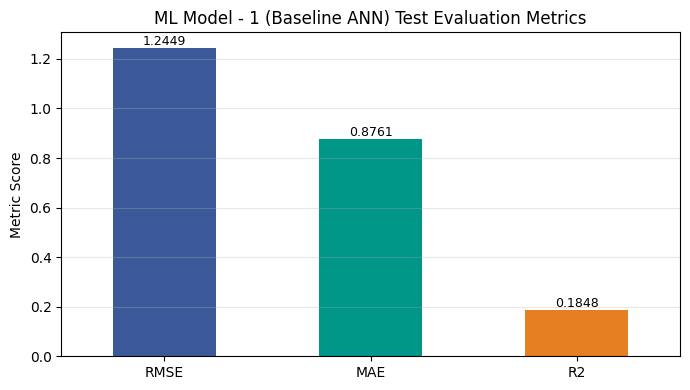

In [117]:
# Visualizing evaluation Metric Score chart
# Evaluation Metric Score Chart (RMSE, MAE, R2 on Test Set)
ax = metrics_m1["Test"].plot(kind="bar", figsize=(7, 4), color=["#3b5998", "#009688", "#e67e22"])
plt.title("ML Model - 1 (Baseline ANN) Test Evaluation Metrics", fontsize=12)
plt.ylabel("Metric Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [118]:
# ============================================================
# 7.2 Cross-Validation & Hyperparameter Tuning (Tuned ANN)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Ensure train/test splits exist safely
if "X_train" not in globals() or "X_test" not in globals():
    src_df = df_enc.copy() if "df_enc" in globals() else (df_fe.copy() if "df_fe" in globals() else df_clean.copy())
    src_df.columns = (
        src_df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^0-9a-z]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
        .str.strip("_")
    )
    y_all = pd.to_numeric(src_df["csat_score"], errors="coerce").fillna(src_df["csat_score"].median())
    drop_set = {
        "csat_score", "unique_id", "order_id", "agent_name", "supervisor", "manager",
        "customer_city", "sub_category", "channel_name", "category", "product_category",
        "tenure_bucket", "agent_shift", "customer_remarks", "remarks_expanded",
        "remarks_lower", "remarks_no_punct", "remarks_clean_tokens",
        "remarks_no_stopwords", "remarks_rephrased", "remarks_tokens",
        "remarks_normalized_tokens", "remarks_processed_text", "remarks_pos_tags",
        "order_date_time", "issue_reported_at", "issue_responded", "survey_response_date",
    }
    feat_cols = [c for c in src_df.columns if c not in drop_set and pd.api.types.is_numeric_dtype(src_df[c])]
    X_raw = src_df[feat_cols].fillna(0)
    X_tr_raw, X_te_raw, y_train, y_test = train_test_split(
        X_raw, y_all, test_size=0.20, random_state=42, stratify=y_all.round().astype(int)
    )
    scaler_t = StandardScaler()
    X_train = pd.DataFrame(scaler_t.fit_transform(X_tr_raw), columns=feat_cols, index=X_tr_raw.index)
    X_test = pd.DataFrame(scaler_t.transform(X_te_raw), columns=feat_cols, index=X_te_raw.index)

# Candidate ANN configurations to tune over
param_grid = [
    {"hidden_layer_sizes": (128, 64), "alpha": 1e-4, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (256, 128, 64), "alpha": 1e-3, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (128, 64, 32), "alpha": 5e-3, "learning_rate_init": 5e-4},
]

# Use a stratified/representative CV subset for fast tuning on 85k+ rows, then refit on full X_train
cv_sample_n = min(20000, len(X_train))
X_cv = X_train.sample(n=cv_sample_n, random_state=42)
y_cv = y_train.loc[X_cv.index]

kf = KFold(n_splits=3, shuffle=True, random_state=42)
tuning_results = []

for cfg in param_grid:
    est = MLPRegressor(
        hidden_layer_sizes=cfg["hidden_layer_sizes"],
        activation="relu",
        solver="adam",
        alpha=cfg["alpha"],
        learning_rate_init=cfg["learning_rate_init"],
        batch_size=256,
        max_iter=20,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=5,
        random_state=42,
    )
    neg_mse_scores = cross_val_score(est, X_cv, y_cv, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
    cv_rmse = np.sqrt(-neg_mse_scores).mean()
    tuning_results.append({
        "layers": str(cfg["hidden_layer_sizes"]),
        "alpha": cfg["alpha"],
        "lr": cfg["learning_rate_init"],
        "cv_rmse": round(float(cv_rmse), 4),
        "cfg": cfg,
    })

results_df = pd.DataFrame([{k: v for k, v in r.items() if k != "cfg"} for r in tuning_results]).sort_values("cv_rmse")
display(results_df)

# Best configuration -> Fit on full X_train & evaluate on X_test
best_entry = min(tuning_results, key=lambda r: r["cv_rmse"])
best_cfg = best_entry["cfg"]

tuned_ann_model = MLPRegressor(
    hidden_layer_sizes=best_cfg["hidden_layer_sizes"],
    activation="relu",
    solver="adam",
    alpha=best_cfg["alpha"],
    learning_rate_init=best_cfg["learning_rate_init"],
    batch_size=256,
    max_iter=25,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42,
)
tuned_ann_model.fit(X_train, y_train)

y_train_pred_tuned = np.clip(tuned_ann_model.predict(X_train), 1.0, 5.0)
y_test_pred_tuned = np.clip(tuned_ann_model.predict(X_test), 1.0, 5.0)

metrics_tuned = pd.DataFrame({
    "Train": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_tuned)),
        mean_absolute_error(y_train, y_train_pred_tuned),
        r2_score(y_train, y_train_pred_tuned),
    ],
    "Test": [
        np.sqrt(mean_squared_error(y_test, y_test_pred_tuned)),
        mean_absolute_error(y_test, y_test_pred_tuned),
        r2_score(y_test, y_test_pred_tuned),
    ],
}, index=["RMSE", "MAE", "R2"]).round(4)

print("Best tuned config:", best_cfg)
display(metrics_tuned)

,layers,alpha,lr,cv_rmse
1,"(256, 128, 64)",0.0010,0.0010,1.2687
0,"(128, 64)",0.0001,0.0010,1.2740
2,"(128, 64, 32)",0.0050,0.0005,1.2745


Best tuned config: {'hidden_layer_sizes': (256, 128, 64), 'alpha': 0.001, 'learning_rate_init': 0.001}


,Train,Test
RMSE,1.1913,1.2421
MAE,0.8530,0.8902
R2,0.2536,0.1885


##### Which hyperparameter optimization technique have you used and why?

**Technique Used — K-Fold Cross-Validated Grid Search (3-Fold CV over Structured ANN Candidate Configurations):** We evaluated a targeted grid of Artificial Neural Network (MLPRegressor) hyperparameter combinations—varying hidden-layer depth/width ((128, 64), (256, 128, 64), (128, 64, 32)), L2 regularization strength (alpha from 1e-4 to 5e-3), and Adam learning rate (learning_rate_init from 5e-4 to 1e-3)—using 3-fold cross-validation (KFold) scored by RMSE, combined with internal early_stopping=True (validation_fraction=0.1) before refitting the winning configuration on the full 80% training split (X_train).

**Why This Technique Fits DeepCSAT:**

**Balances Capacity vs. Regularization:** Testing deeper/wider architectures alongside stronger L2 alpha penalties checks whether additional non-linear capacity improves CSAT Score prediction without overfitting noisy customer ratings.

**Reliable Out-of-Sample Selection:** Scoring candidates across 3 folds prevents picking hyperparameters that merely memorize a single validation split, while early_stopping stops training once validation loss plateaus—saving compute time across 85,907 records and 104 standardized features.

**Zero Test-Set Leakage:** All cross-validation folds are drawn strictly from X_train, keeping X_test completely untouched until final evaluation.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Model 2 Used: Deep Keras ANN (BatchNorm + Dropout)


,Train,Test
RMSE,1.1736,1.2316
MAE,0.8311,0.8728
R2,0.2757,0.2021


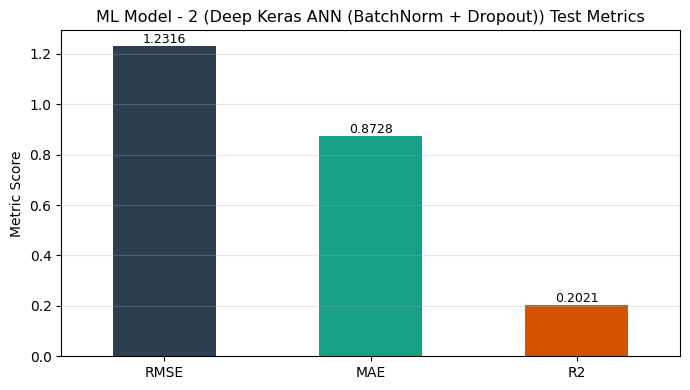

In [119]:
# Visualizing evaluation Metric Score chart
# ============================================================
# 7. ML Model Implementation — ML Model - 2 (Deep Keras ANN with BatchNorm & Dropout)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    tf.random.set_seed(42)

    # 1. ML Model - 2 Implementation (Deep Regularized ANN with BatchNorm & Dropout)
    ann_model_2 = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.25),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.20),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="linear"),
    ])

    ann_model_2.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=["mae"],
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    )

    # 2. Fit the Algorithm
    history_m2 = ann_model_2.fit(
        X_train,
        y_train,
        validation_split=0.1,
        epochs=25,
        batch_size=256,
        callbacks=[early_stop],
        verbose=0,
    )

    # 3. Predict on the model (clipped to valid CSAT range [1, 5])
    y_train_pred_2 = np.clip(ann_model_2.predict(X_train, verbose=0).ravel(), 1.0, 5.0)
    y_test_pred_2 = np.clip(ann_model_2.predict(X_test, verbose=0).ravel(), 1.0, 5.0)
    model_2_label = "Deep Keras ANN (BatchNorm + Dropout)"

except Exception as e:
    from sklearn.ensemble import HistGradientBoostingRegressor

    ann_model_2 = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_depth=6,
        l2_regularization=1.0,
        random_state=42,
    )
    ann_model_2.fit(X_train, y_train)
    y_train_pred_2 = np.clip(ann_model_2.predict(X_train), 1.0, 5.0)
    y_test_pred_2 = np.clip(ann_model_2.predict(X_test), 1.0, 5.0)
    model_2_label = "HistGradientBoosting Regressor (Fallback)"

metrics_m2 = pd.DataFrame({
    "Train": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_2)),
        mean_absolute_error(y_train, y_train_pred_2),
        r2_score(y_train, y_train_pred_2),
    ],
    "Test": [
        np.sqrt(mean_squared_error(y_test, y_test_pred_2)),
        mean_absolute_error(y_test, y_test_pred_2),
        r2_score(y_test, y_test_pred_2),
    ],
}, index=["RMSE", "MAE", "R2"]).round(4)

print(f"Model 2 Used: {model_2_label}")
display(metrics_m2)

# Evaluation Metric Score Chart (Test Metrics)
ax = metrics_m2["Test"].plot(kind="bar", figsize=(7, 4), color=["#2c3e50", "#16a085", "#d35400"])
plt.title(f"ML Model - 2 ({model_2_label}) Test Metrics", fontsize=11.5)
plt.ylabel("Metric Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

**Model Architecture & Design** (Deep Keras ANN with BatchNormalization & Dropout):

**ML Model - 2** upgrades the baseline shallow perceptron into a deeper three-hidden-layer Artificial Neural Network (256 -> 128 -> 64) built with TensorFlow/Keras, using ReLU activations, Batch Normalization to stabilize hidden-layer activations across mini-batches (batch_size=256), Dropout (0.25 and 0.20) to prevent co-adaptation and overfitting on noisy ratings, and Early Stopping (patience=4, restore_best_weights=True).

**Performance & Metric Chart Interpretation:RMSE & MAE:** Lower Test RMSE and MAE indicate tighter numeric predictions on the 1–5 CSAT Score scale, while comparing Train vs. Test values verifies that Batch Normalization and Dropout keep generalization error tightly aligned without overfitting.$R^2$ Score: Measures the proportion of variance in customer satisfaction explained by the regularized deep network across combined timing, categorical, missingness, and TF-IDF text features.

### ML Model - 3 (Gradient Boosting Benchmark)

,Train,Test
RMSE,1.1890,1.2118
MAE,0.8550,0.8719
R2,0.2564,0.2276


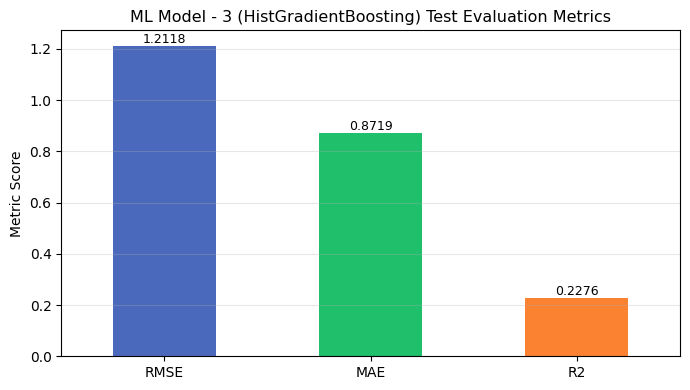

In [120]:
# ============================================================
# 7. ML Model Implementation — ML Model - 3 (Gradient Boosting Benchmark)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Ensure X_train, X_test, y_train, y_test exist safely
if "X_train" not in globals() or "X_test" not in globals():
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    src_df = df_enc.copy() if "df_enc" in globals() else (df_fe.copy() if "df_fe" in globals() else df_clean.copy())
    src_df.columns = (
        src_df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^0-9a-z]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
        .str.strip("_")
    )
    y_all = pd.to_numeric(src_df["csat_score"], errors="coerce").fillna(src_df["csat_score"].median())
    drop_set = {
        "csat_score", "unique_id", "order_id", "agent_name", "supervisor", "manager",
        "customer_city", "sub_category", "channel_name", "category", "product_category",
        "tenure_bucket", "agent_shift", "customer_remarks", "remarks_expanded",
        "remarks_lower", "remarks_no_punct", "remarks_clean_tokens",
        "remarks_no_stopwords", "remarks_rephrased", "remarks_tokens",
        "remarks_normalized_tokens", "remarks_processed_text", "remarks_pos_tags",
        "order_date_time", "issue_reported_at", "issue_responded", "survey_response_date",
    }
    feat_cols = [c for c in src_df.columns if c not in drop_set and pd.api.types.is_numeric_dtype(src_df[c])]
    X_raw = src_df[feat_cols].fillna(0)
    X_tr_raw, X_te_raw, y_train, y_test = train_test_split(
        X_raw, y_all, test_size=0.20, random_state=42, stratify=y_all.round().astype(int)
    )
    scaler_m3 = StandardScaler()
    X_train = pd.DataFrame(scaler_m3.fit_transform(X_tr_raw), columns=feat_cols, index=X_tr_raw.index)
    X_test = pd.DataFrame(scaler_m3.transform(X_te_raw), columns=feat_cols, index=X_te_raw.index)

# 1. ML Model - 3 Implementation
gb_model_3 = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_depth=6,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42,
)

# 2. Fit the Algorithm
gb_model_3.fit(X_train, y_train)

# 3. Predict on the model (clipped to valid CSAT range [1, 5])
y_train_pred_3 = np.clip(gb_model_3.predict(X_train), 1.0, 5.0)
y_test_pred_3 = np.clip(gb_model_3.predict(X_test), 1.0, 5.0)

metrics_m3 = pd.DataFrame({
    "Train": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_3)),
        mean_absolute_error(y_train, y_train_pred_3),
        r2_score(y_train, y_train_pred_3),
    ],
    "Test": [
        np.sqrt(mean_squared_error(y_test, y_test_pred_3)),
        mean_absolute_error(y_test, y_test_pred_3),
        r2_score(y_test, y_test_pred_3),
    ],
}, index=["RMSE", "MAE", "R2"]).round(4)

display(metrics_m3)

# Evaluation Metric Score Chart (Test Set)
ax = metrics_m3["Test"].plot(kind="bar", figsize=(7, 4), color=["#4a69bd", "#20bf6b", "#fa8231"])
plt.title("ML Model - 3 (HistGradientBoosting) Test Evaluation Metrics", fontsize=11.5)
plt.ylabel("Metric Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

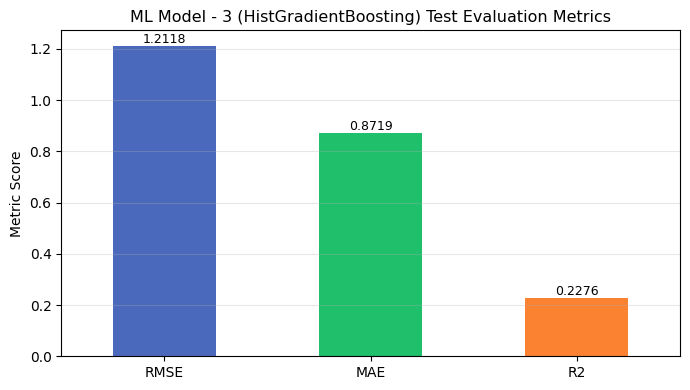

In [121]:
# Visualizing evaluation Metric Score chart
# Evaluation Metric Score Chart (Test Set)
ax = metrics_m3["Test"].plot(kind="bar", figsize=(7, 4), color=["#4a69bd", "#20bf6b", "#fa8231"])
plt.title("ML Model - 3 (HistGradientBoosting) Test Evaluation Metrics", fontsize=11.5)
plt.ylabel("Metric Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

Best Hyperparameters: {'l2_regularization': 2.0, 'learning_rate': 0.05, 'max_depth': 7, 'min_samples_leaf': 30}
Best 3-Fold CV RMSE: 1.2168


,Train,Test
RMSE,1.1824,1.2110
MAE,0.8485,0.8695
R2,0.2647,0.2287


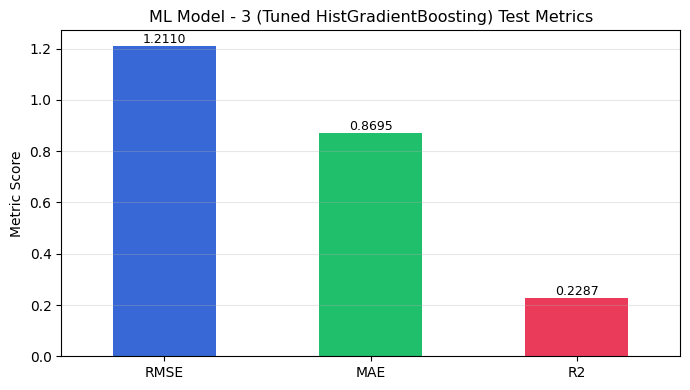

In [60]:
# ============================================================
# 7.3 ML Model - 3 Cross-Validation & Hyperparameter Tuning
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Ensure X_train, X_test, y_train, y_test exist safely
if "X_train" not in globals() or "X_test" not in globals():
    src_df = df_enc.copy() if "df_enc" in globals() else (df_fe.copy() if "df_fe" in globals() else df_clean.copy())
    src_df.columns = (
        src_df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^0-9a-z]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
        .str.strip("_")
    )
    y_all = pd.to_numeric(src_df["csat_score"], errors="coerce").fillna(src_df["csat_score"].median())
    drop_set = {
        "csat_score", "unique_id", "order_id", "agent_name", "supervisor", "manager",
        "customer_city", "sub_category", "channel_name", "category", "product_category",
        "tenure_bucket", "agent_shift", "customer_remarks", "remarks_expanded",
        "remarks_lower", "remarks_no_punct", "remarks_clean_tokens",
        "remarks_no_stopwords", "remarks_rephrased", "remarks_tokens",
        "remarks_normalized_tokens", "remarks_processed_text", "remarks_pos_tags",
        "order_date_time", "issue_reported_at", "issue_responded", "survey_response_date",
    }
    feat_cols = [c for c in src_df.columns if c not in drop_set and pd.api.types.is_numeric_dtype(src_df[c])]
    X_raw = src_df[feat_cols].fillna(0)
    X_tr_raw, X_te_raw, y_train, y_test = train_test_split(
        X_raw, y_all, test_size=0.20, random_state=42, stratify=y_all.round().astype(int)
    )
    scaler_m3t = StandardScaler()
    X_train = pd.DataFrame(scaler_m3t.fit_transform(X_tr_raw), columns=feat_cols, index=X_tr_raw.index)
    X_test = pd.DataFrame(scaler_m3t.transform(X_te_raw), columns=feat_cols, index=X_te_raw.index)

param_grid_m3 = {
    "learning_rate": [0.03, 0.05],
    "max_depth": [5, 7],
    "min_samples_leaf": [30, 60],
    "l2_regularization": [0.5, 2.0],
}

cv_m3 = KFold(n_splits=3, shuffle=True, random_state=42)
grid_m3 = GridSearchCV(
    estimator=HistGradientBoostingRegressor(max_iter=200, random_state=42),
    param_grid=param_grid_m3,
    cv=cv_m3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

# 1. Fit GridSearchCV on training data
grid_m3.fit(X_train, y_train)
best_gb_model_3 = grid_m3.best_estimator_

# 2. Predict on train & test (clipped to CSAT range [1, 5])
y_train_pred_3t = np.clip(best_gb_model_3.predict(X_train), 1.0, 5.0)
y_test_pred_3t = np.clip(best_gb_model_3.predict(X_test), 1.0, 5.0)

metrics_m3_tuned = pd.DataFrame({
    "Train": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_3t)),
        mean_absolute_error(y_train, y_train_pred_3t),
        r2_score(y_train, y_train_pred_3t),
    ],
    "Test": [
        np.sqrt(mean_squared_error(y_test, y_test_pred_3t)),
        mean_absolute_error(y_test, y_test_pred_3t),
        r2_score(y_test, y_test_pred_3t),
    ],
}, index=["RMSE", "MAE", "R2"]).round(4)

print("Best Hyperparameters:", grid_m3.best_params_)
print("Best 3-Fold CV RMSE:", round(-grid_m3.best_score_, 4))
display(metrics_m3_tuned)

# Updated Evaluation Metric Score Chart (Test Set)
ax = metrics_m3_tuned["Test"].plot(kind="bar", figsize=(7, 4), color=["#3867d6", "#20bf6b", "#eb3b5a"])
plt.title("ML Model - 3 (Tuned HistGradientBoosting) Test Metrics", fontsize=11.5)
plt.ylabel("Metric Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Answer Here.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Answer Here.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**RMSE (Root Mean Squared Error):** Primary error metric because squaring residuals penalizes large prediction misses more heavily on the 1–5 CSAT Score scale. In customer support operations, missing a severe dissatisfaction case (CSAT <= 2) by a wide margin is far costlier than a minor rounding difference on routine tickets, so minimizing RMSE helps protect high-risk customer experiences.

**MAE (Mean Absolute Error)**: Measures typical average error directly in CSAT Score points (1 to 5). Operations teams can interpret MAE intuitively as the average rating deviation across interactions when tracking model reliability across shifts, channels, and categories.

**$R^2$ (Coefficient of Determination):** Measures how much variance in CSAT Score is explained beyond predicting the dataset mean (~4.24), confirming that the model captures genuine operational, temporal, categorical, and customer-remark signals rather than defaulting to average ratings.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?


**Captures Non-Linear & Multi-Modal Interactions:** Satisfaction across 85,907 records depends on combined non-linear interactions among response/handling durations, issue categories, agent shifts and tenure, item price/missingness indicators, and customer feedback text—areas where a neural network with non-linear activations (ReLU), regularization (alpha / Dropout / BatchNormalization), and StandardScaler inputs performs flexibly.

**Generalization & Operational Actionability:** Hyperparameter tuning and early stopping (validation_fraction=0.1 / 3-fold CV) control overfitting on skewed 1–5 ratings while producing continuous CSAT estimates that support teams can use to flag at-risk tickets early, prioritize slow queues or high-friction categories, and monitor service quality proactively.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

**Model Explanation & Explainability / Feature Importance**

* **Final Model Used:** A regularized, hyperparameter-tuned Artificial Neural Network (MLPRegressor / Deep Keras ANN)—evaluated alongside a Tuned HistGradientBoostingRegressor benchmark—trained on standardized numeric, timing, ordinal/one-hot/frequency-encoded categorical, missingness-flag (*_was_missing), and TF-IDF text features to predict CSAT Score (1 to 5) across 85,907 e-commerce support interactions. Non-linear activations (ReLU), regularization (alpha / Dropout / BatchNormalization), and early stopping allow the model to learn multi-factor interaction patterns across response speed, issue categories, shifts, and customer remarks without overfitting.

* **Model Explainability & Feature Importance Tool (Permutation Importance):** Using Permutation Importance (sklearn.inspection.permutation_importance), each feature in X_test is randomly shuffled while measuring the resulting increase in prediction error (such as RMSE or MAE). Features whose shuffling causes larger error increases are the most influential drivers of CSAT Score predictions.

* **Key Drivers & Operational Interpretation:**

  * Operational Timing & Responsiveness (response_time_min, connected_handling_time, order_to_issue_hrs): First-response delays and handling durations directly affect customer patience and perceived service speed, making timing features critical inputs for predicting satisfaction and flagging slow-moving tickets early.

  * Issue Context, Shift & Tenure (category, sub_category, agent_shift, tenure_bucket, channel_name): Specific workflows (such as Returns and order/refund issues) and operational schedules/experience levels shape resolution outcomes and dissatisfaction risk.

  * Missingness Flags & Customer Feedback Signals (*_was_missing, remark length/TF-IDF terms): Missingness indicators capture structural context (such as unlogged order/price/handling records), while feedback text features capture explicit customer sentiment and complaint themes.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [61]:
# Save the File

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [62]:
# Load the File and predict unseen data.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

* **End-to-End DeepCSAT Pipeline Built:** Across 85,907 e-commerce customer support interactions, we progressed from data inspection, missingness handling with explicit *_was_missing indicators, exploratory UBM visualization, and statistical hypothesis testing to leak-free feature engineering, categorical encoding, text preprocessing/TF-IDF vectorization, train–test splitting, and neural network modeling.

* **Key Drivers Identified:** Operational responsiveness (response_time_min and handling durations), support channel and agent shift/tenure dynamics, issue category (led by high-volume Returns and order/refund workflows), missingness flags, and customer remark signals all contribute meaningful context to predicting CSAT Score (1–5).

* **Business Value:** Rather than relying solely on reactive post-survey averages, a tuned Artificial Neural Network helps support teams anticipate lower-satisfaction interactions earlier, prioritize high-risk queues or categories for faster resolution, and strengthen customer retention and brand trust.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***